# Entendimiento del problema

- Detección de fraude
- Recall
- Sensibilidad

# Análisis Exploratorio de Datos

## Importar librerías necesarias

In [269]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import umap
from pathlib import Path
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_auc_score
from sklearn.manifold import TSNE

## Importación de los datos

In [270]:
ruta = Path("..") / "data" / "raw" / "creditcard.csv"

def load_data():
    df = pd.read_csv(ruta)
    return df

In [271]:
df = load_data()

In [272]:
print(type(df))

<class 'pandas.DataFrame'>


## Errors and sensitive checks

In [273]:
df.head(5)

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


In [274]:
df.shape

(284807, 31)

In [275]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 284807 entries, 0 to 284806
Data columns (total 31 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   Time    284807 non-null  float64
 1   V1      284807 non-null  float64
 2   V2      284807 non-null  float64
 3   V3      284807 non-null  float64
 4   V4      284807 non-null  float64
 5   V5      284807 non-null  float64
 6   V6      284807 non-null  float64
 7   V7      284807 non-null  float64
 8   V8      284807 non-null  float64
 9   V9      284807 non-null  float64
 10  V10     284807 non-null  float64
 11  V11     284807 non-null  float64
 12  V12     284807 non-null  float64
 13  V13     284807 non-null  float64
 14  V14     284807 non-null  float64
 15  V15     284807 non-null  float64
 16  V16     284807 non-null  float64
 17  V17     284807 non-null  float64
 18  V18     284807 non-null  float64
 19  V19     284807 non-null  float64
 20  V20     284807 non-null  float64
 21  V21     284807 non-nu

In [276]:
print(f"El dataset presenta una cantidad de nulos: {df.isnull().sum().sum()}")
print(f"El dataset presenta una cantidad de duplicados: {df.duplicated().sum()}")

El dataset presenta una cantidad de nulos: 0
El dataset presenta una cantidad de duplicados: 1081


In [277]:
df.duplicated().groupby(df["Class"]).sum()

Class
0    1062
1      19
dtype: int64

In [278]:
print(f"% Duplicados en transacciones no fraude: {df[df['Class'] == 0].duplicated().mean() * 100:.2f}%")

print(f"% Duplicados en transacciones fraude: {df[df['Class'] == 1].duplicated().mean() * 100:.2f}%")

% Duplicados en transacciones no fraude: 0.37%
% Duplicados en transacciones fraude: 3.86%


In [279]:
df = df.drop_duplicates()
print(f"El dataset presenta una cantidad de duplicados: {df.duplicated().sum()}")

El dataset presenta una cantidad de duplicados: 0


## Mapeo y adición de variables

In [280]:
def variables_tiempo (dfh):
    dfh['Hour'] = ((dfh['Time'] // 3600) % 24).astype(int)
    return dfh

In [281]:
df = variables_tiempo(df)

## Creación de los dataframes a usar

### Dividir el dataframe en train y test

In [282]:
def df_split (dfs):
    dtr, dts = train_test_split(dfs, test_size=0.2, random_state=42, stratify=dfs['Class'])

    tx = dtr.drop('Class', axis=1)
    ty = dtr['Class']

    return dtr, dts, tx, ty

In [283]:
df_train, df_test, train_x, train_y = df_split(df)

ruta_data = Path("..") / "Data" / "raw"
df_train.to_csv(ruta_data / "train.csv", index=False)
df_test.to_csv(ruta_data / "test.csv", index=False)

In [284]:
print(f"Cantidad de registros en df_train: {len(df_train)} y sus dimensiones {df_train.shape}")
print(f"Cantidad de registros en df_test: {len(df_test)} y sus dimensiones {df_test.shape}")

Cantidad de registros en df_train: 226980 y sus dimensiones (226980, 32)
Cantidad de registros en df_test: 56746 y sus dimensiones (56746, 32)


In [285]:
df_plot = df_train.copy()
mapa_clase = {0: 'No fraude', 1: 'Fraude'}
df_plot['Tipo'] = df_plot['Class'].map(mapa_clase)

## Estadisticas descriptivas

In [286]:
print(f"Cantidad de registros que son fraude en el dataset de entrenamiento: {len(df_train[df_train['Class'] == 1])}")
print(f"Cantidad de registros que no son fraude en el dataset de entrenamiento: {len(df_train[df_train['Class'] == 0])}")
print(f"Porcentaje de fraudes en el dataset de entrenamiento: {len(df_train[df_train['Class'] == 1]) / len(df_train) * 100:.2f}%")

Cantidad de registros que son fraude en el dataset de entrenamiento: 378
Cantidad de registros que no son fraude en el dataset de entrenamiento: 226602
Porcentaje de fraudes en el dataset de entrenamiento: 0.17%


In [287]:
df_train.describe().T

,count,mean,std,min,25%,50%,75%,max
Time,226980.0,94900.224390,47488.214282,0.000000,54241.750000,84816.000000,139364.250000,172792.000000
V1,226980.0,0.005027,1.947293,-56.407510,-0.915886,0.018358,1.315404,2.454930
V2,226980.0,-0.005549,1.649617,-72.715728,-0.601108,0.063820,0.801327,22.057729
V3,226980.0,0.002131,1.507270,-33.680984,-0.887261,0.178307,1.027460,9.382558
V4,226980.0,-0.002025,1.416960,-5.683171,-0.849272,-0.021999,0.741399,16.875344
V5,226980.0,0.004941,1.359643,-32.092129,-0.689146,-0.052477,0.615362,34.801666
V6,226980.0,-0.001961,1.323401,-26.160506,-0.768760,-0.275923,0.397381,21.393069
V7,226980.0,0.001480,1.200181,-43.557242,-0.552497,0.040832,0.571905,34.303177
V8,226980.0,-0.000215,1.169342,-73.216718,-0.208633,0.022232,0.325467,20.007208
V9,226980.0,-0.002883,1.094055,-13.434066,-0.644309,-0.052811,0.594205,15.594995


### Medidas de tendencia central

In [288]:
media = {}
mediana = {}
moda = {}

for c, v in df_train.items():
    media[c] = v.mean()
    mediana[c] = v.median()
    moda[c] = v.mode()[0]

df_estadistica = pd.DataFrame(
    {
        'Media': media,
        'Mediana': mediana,
        'Moda' : moda
    }
)

display(df_estadistica)

,Media,Mediana,Moda
Time,94900.224390,84816.000000,3767.000000
V1,0.005027,0.018358,1.245674
V2,-0.005549,0.063820,0.166975
V3,0.002131,0.178307,0.488306
V4,-0.002025,-0.021999,0.635322
V5,0.004941,-0.052477,-0.562777
V6,-0.001961,-0.275923,-1.011073
V7,0.001480,0.040832,0.014953
V8,-0.000215,0.022232,-0.160211
V9,-0.002883,-0.052811,0.170362


### Medidas de dispersión

In [289]:
desv = {}
varianza = {}
rango = {}

for c, v in df_train.items():
    desv[c] = v.std()
    varianza[c] = v.var()
    rango[c] = max(v) - min(v)

df_estadistica['Desv'] = df_estadistica.index.map(desv)
df_estadistica['Varianza'] = df_estadistica.index.map(varianza)
df_estadistica['Rango'] = df_estadistica.index.map(rango)

display(df_estadistica)

,Media,Mediana,Moda,Desv,Varianza,Rango
Time,94900.224390,84816.000000,3767.000000,47488.214282,2.255130e+09,172792.000000
V1,0.005027,0.018358,1.245674,1.947293,3.791951e+00,58.862440
V2,-0.005549,0.063820,0.166975,1.649617,2.721236e+00,94.773457
V3,0.002131,0.178307,0.488306,1.507270,2.271863e+00,43.063542
V4,-0.002025,-0.021999,0.635322,1.416960,2.007776e+00,22.558515
V5,0.004941,-0.052477,-0.562777,1.359643,1.848628e+00,66.893795
V6,-0.001961,-0.275923,-1.011073,1.323401,1.751389e+00,47.553575
V7,0.001480,0.040832,0.014953,1.200181,1.440434e+00,77.860418
V8,-0.000215,0.022232,-0.160211,1.169342,1.367362e+00,93.223927
V9,-0.002883,-0.052811,0.170362,1.094055,1.196956e+00,29.029061


### Medidas de Forma

In [290]:
asimetria = {}
curtosis = {}

for c, v in df_train.items():
    asimetria[c] = v.skew()
    curtosis[c] = v.kurt()

df_estadistica['Asimetría'] = df_estadistica.index.map(asimetria)
df_estadistica['Curtosis'] = df_estadistica.index.map(curtosis)

display(df_estadistica)

,Media,Mediana,Moda,Desv,Varianza,Rango,Asimetría,Curtosis
Time,94900.224390,84816.000000,3767.000000,47488.214282,2.255130e+09,172792.000000,-0.037474,-1.295100
V1,0.005027,0.018358,1.245674,1.947293,3.791951e+00,58.862440,-3.304103,33.784969
V2,-0.005549,0.063820,0.166975,1.649617,2.721236e+00,94.773457,-4.883896,105.275371
V3,0.002131,0.178307,0.488306,1.507270,2.271863e+00,43.063542,-2.124559,23.540649
V4,-0.002025,-0.021999,0.635322,1.416960,2.007776e+00,22.558515,0.680751,2.711514
V5,0.004941,-0.052477,-0.562777,1.359643,1.848628e+00,66.893795,-0.168415,42.301243
V6,-0.001961,-0.275923,-1.011073,1.323401,1.751389e+00,47.553575,1.194313,10.189226
V7,0.001480,0.040832,0.014953,1.200181,1.440434e+00,77.860418,-0.891383,83.657342
V8,-0.000215,0.022232,-0.160211,1.169342,1.367362e+00,93.223927,-8.008567,211.074837
V9,-0.002883,-0.052811,0.170362,1.094055,1.196956e+00,29.029061,0.535307,3.561212


### Medidas de posición relativa

In [291]:
cuartiles = df_train.quantile([0.25, 0.50, 0.75]).T
cuartiles = cuartiles.round(2)
display(cuartiles)


,0.25,0.50,0.75
Time,54241.75,84816.00,139364.25
V1,-0.92,0.02,1.32
V2,-0.60,0.06,0.80
V3,-0.89,0.18,1.03
V4,-0.85,-0.02,0.74
V5,-0.69,-0.05,0.62
V6,-0.77,-0.28,0.40
V7,-0.55,0.04,0.57
V8,-0.21,0.02,0.33
V9,-0.64,-0.05,0.59


## Análisis Univariante 

### Variables cuantitativas

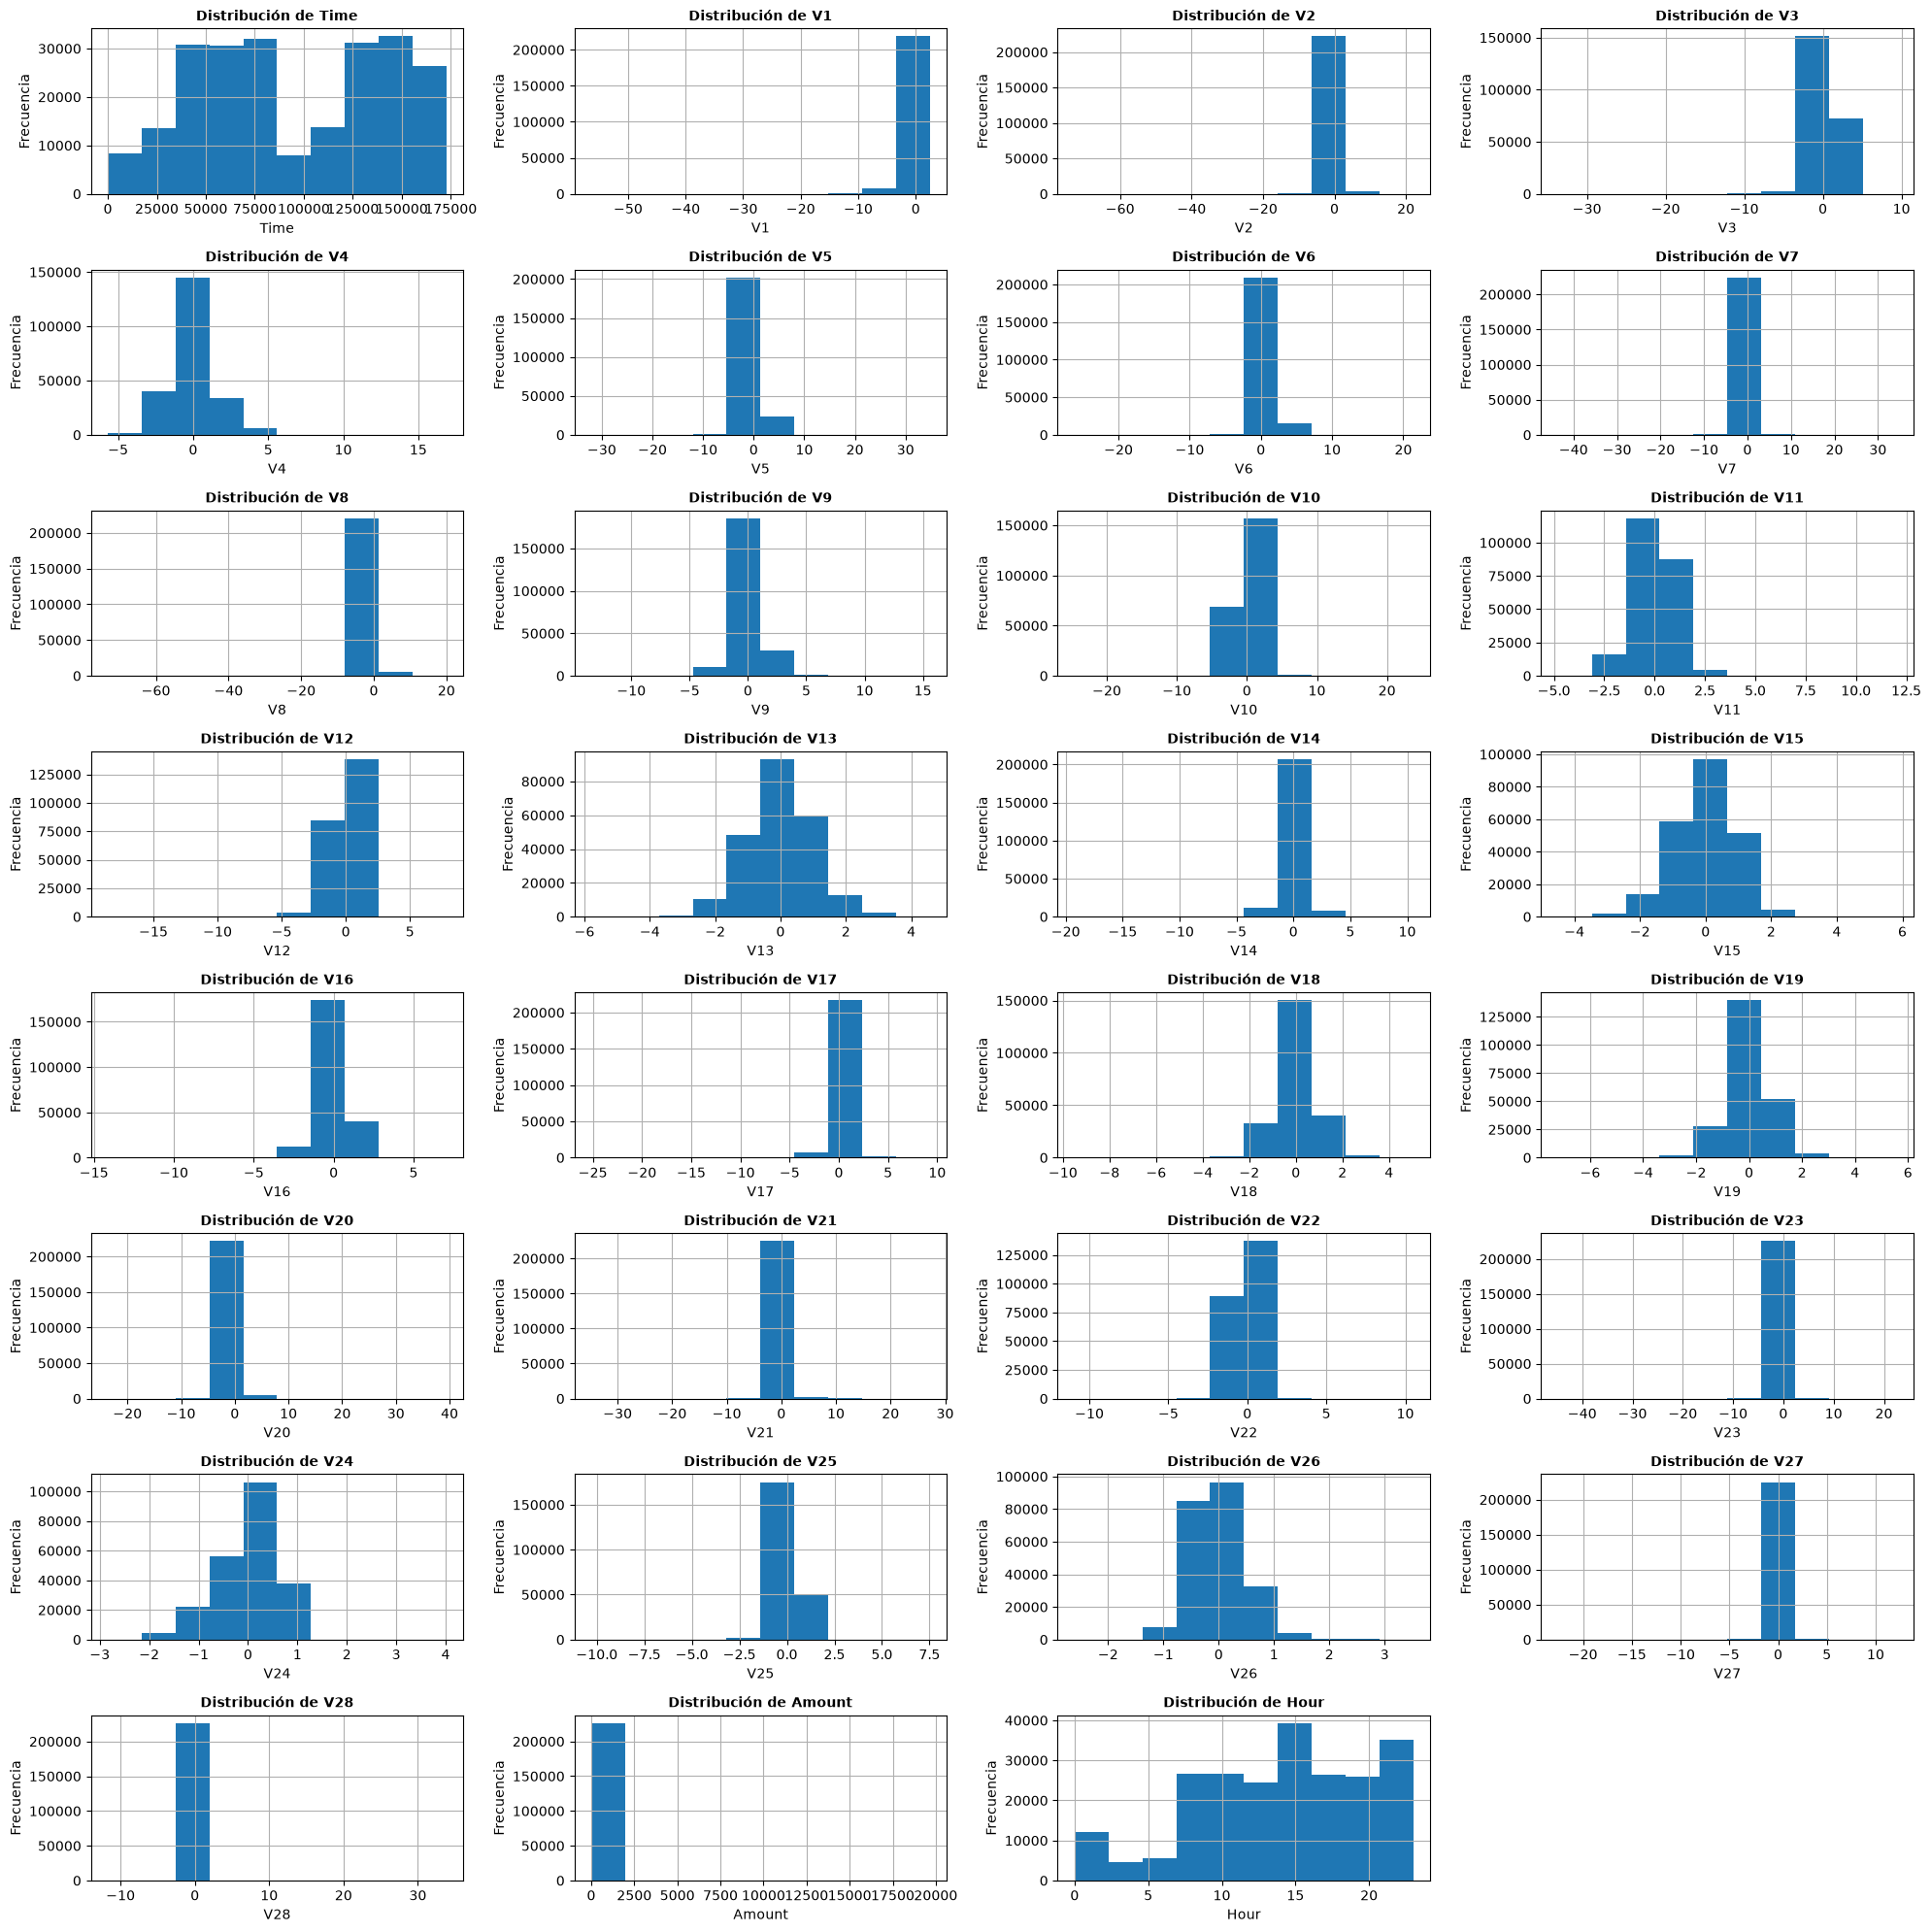

In [292]:
cols = [c for c in df_train.columns if c != "Class"]
fig, axes = plt.subplots(8, 4, figsize=(20, 20))

for ax, col in zip(axes.flat, cols):
    df_train[col].hist(ax=ax)
    
    ax.set_title(f"Distribución de {col}", fontsize=10, fontweight="bold")
    ax.set_xlabel(col)
    ax.set_ylabel("Frecuencia")

for ax in axes.flat[len(cols):]:
    ax.set_visible(False)

plt.tight_layout()
plt.show()

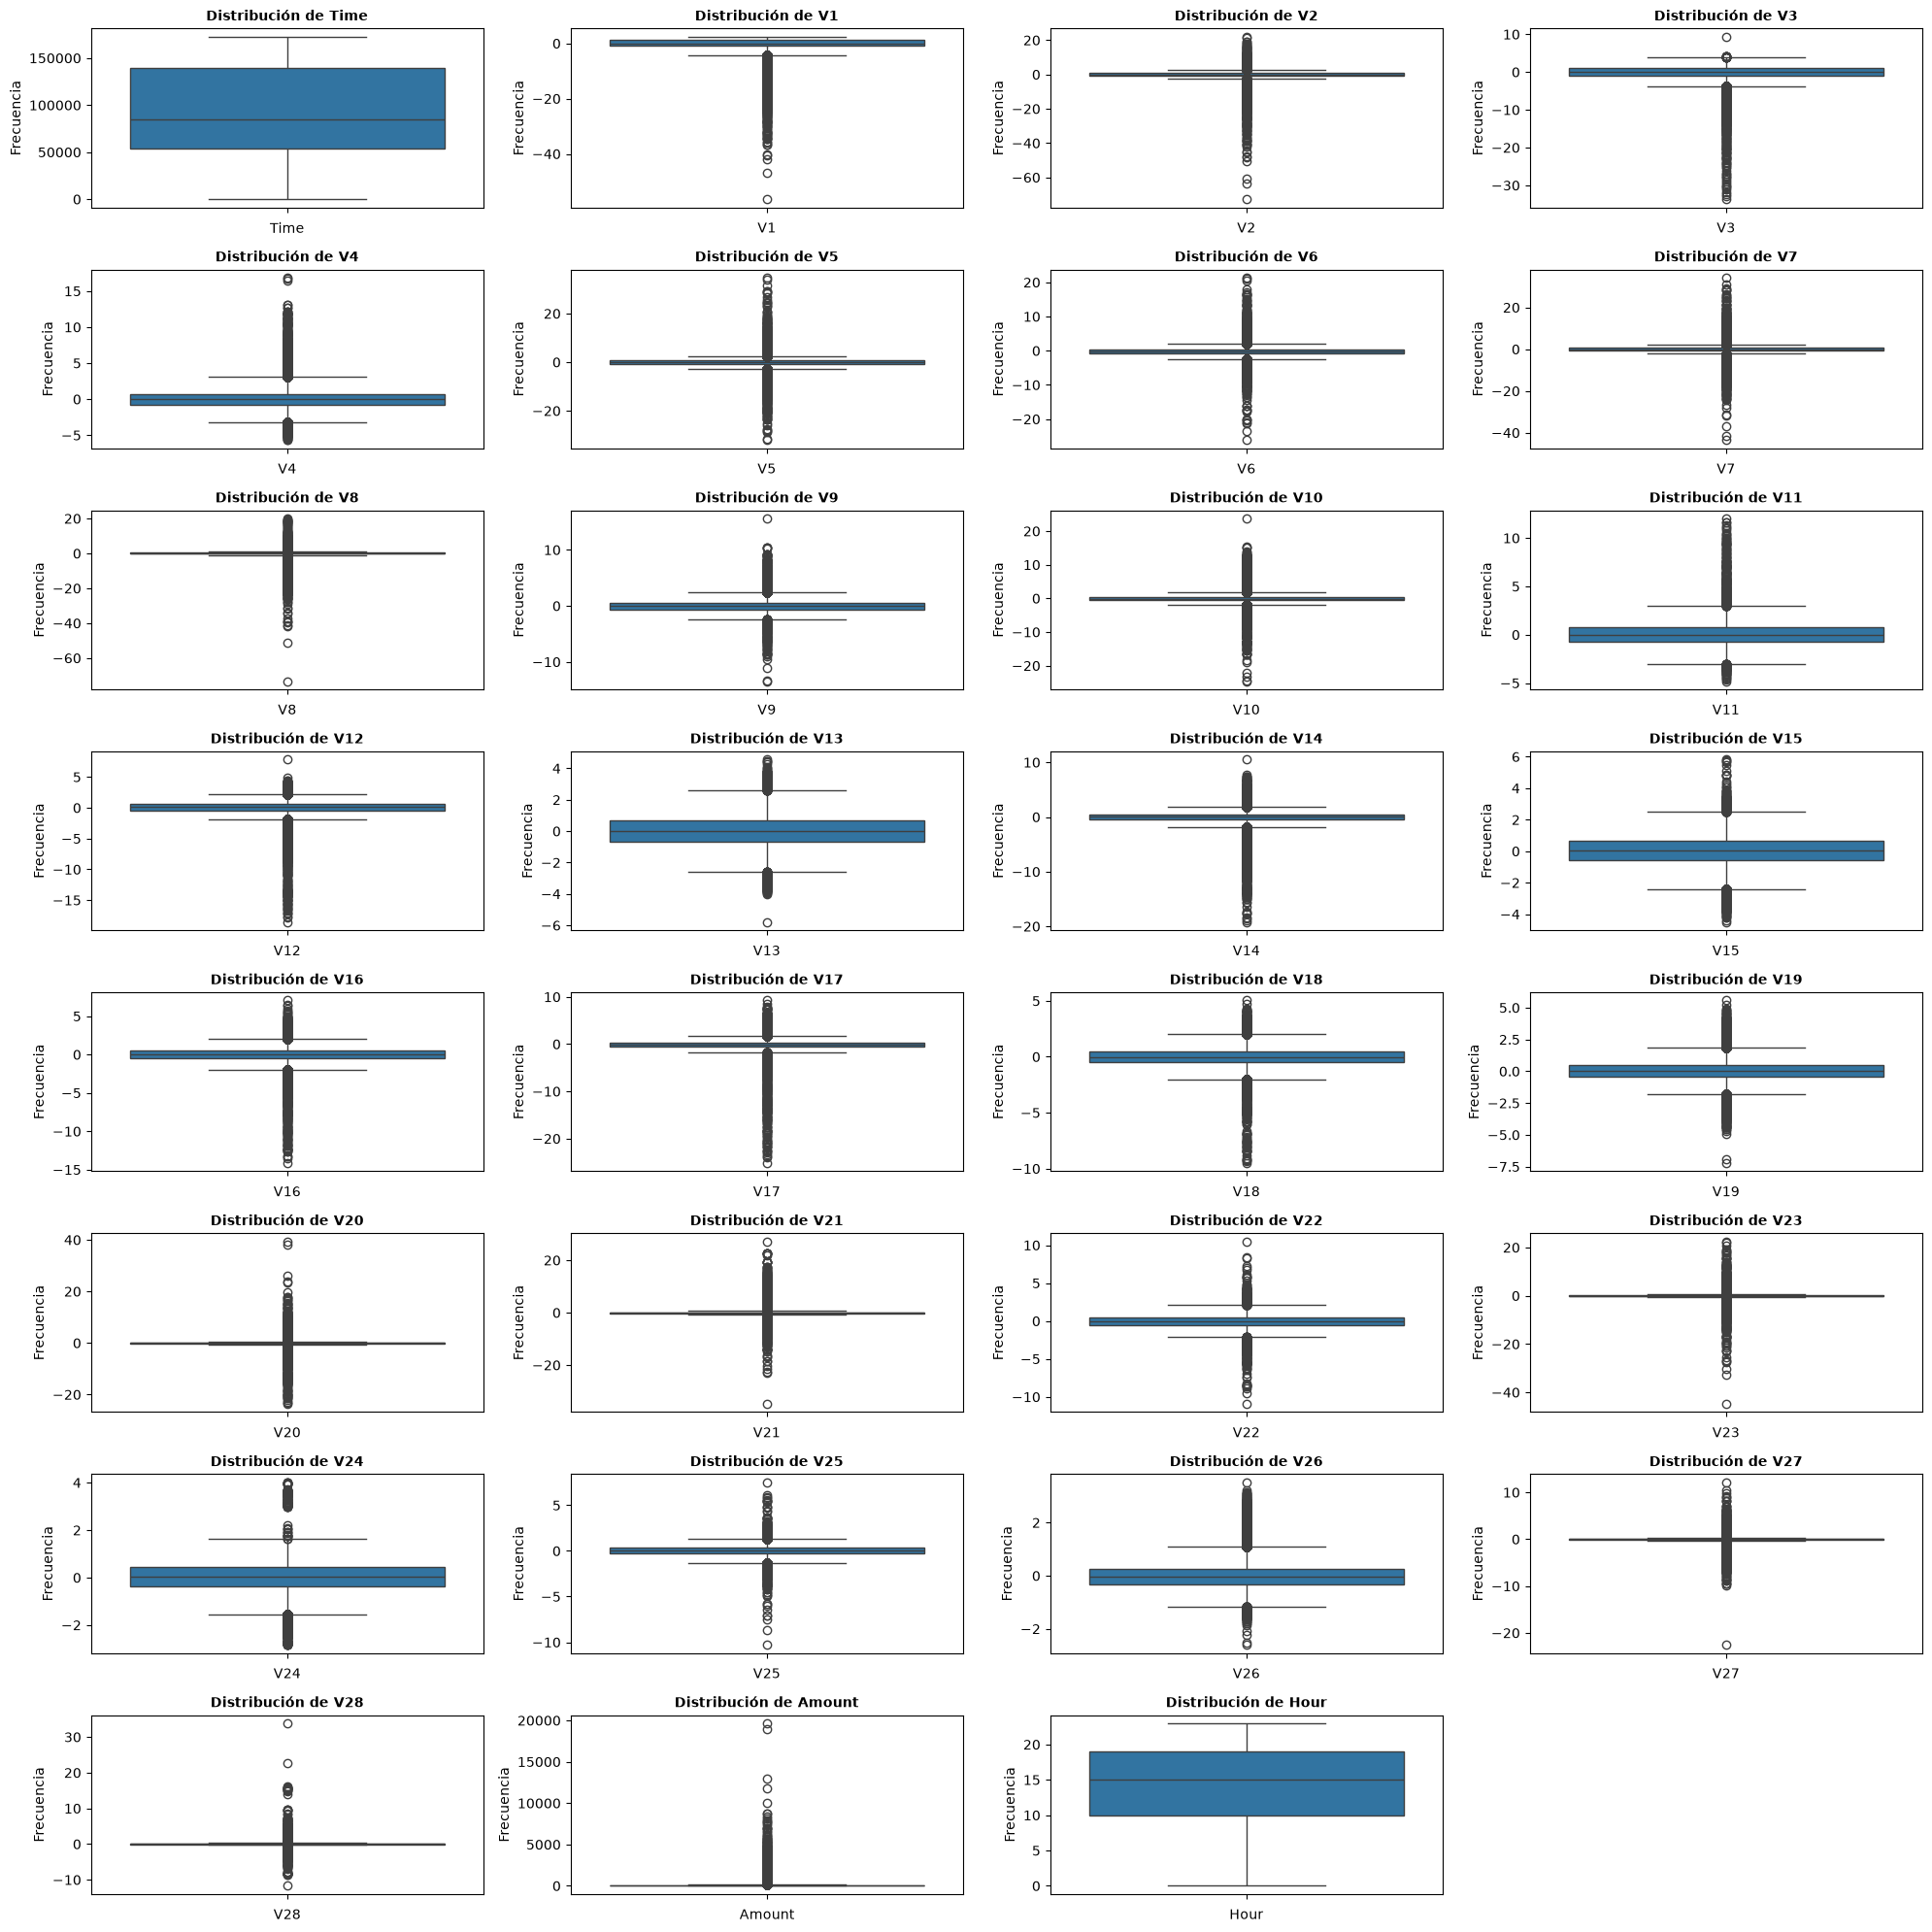

In [293]:
fig, axes = plt.subplots(8, 4, figsize=(20, 20))

for ax, col in zip(axes.flat, cols):
    sns.boxplot(y=df_train[col], ax=ax)
    ax.set_title(f"Distribución de {col}", fontsize=10, fontweight="bold")
    ax.set_xlabel(col)
    ax.set_ylabel("Frecuencia")

for ax in axes.flat[len(cols):]:
    ax.set_visible(False)

plt.tight_layout()
plt.show()

### Análisis de Amount 

#### Valores cero

In [294]:
ceros = df_train[df_train["Amount"] == 0]
print(f"Transacciones con Amount = 0: {len(ceros)} | fraudes: {ceros['Class'].sum()}")
print(f"Tasa de fraude con Amount = 0: {ceros['Class'].mean() * 100:.2f}% (tasa base: {df_train['Class'].mean() * 100:.2f}%)")

Transacciones con Amount = 0: 1430 | fraudes: 18
Tasa de fraude con Amount = 0: 1.26% (tasa base: 0.17%)


#### Manejo de outliers

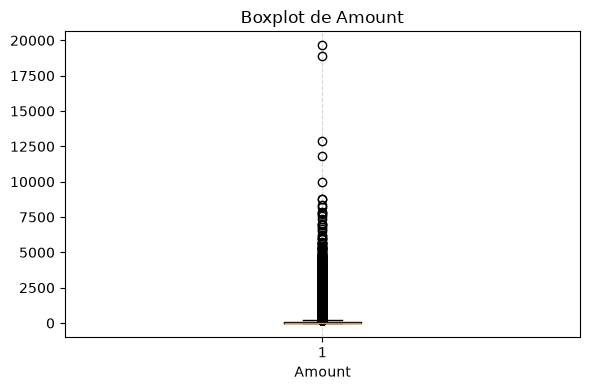

In [295]:
plt.figure(figsize=(6, 4))
plt.boxplot(df_plot["Amount"])

plt.title("Boxplot de Amount")
plt.xlabel("Amount")
plt.grid(axis="x", linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

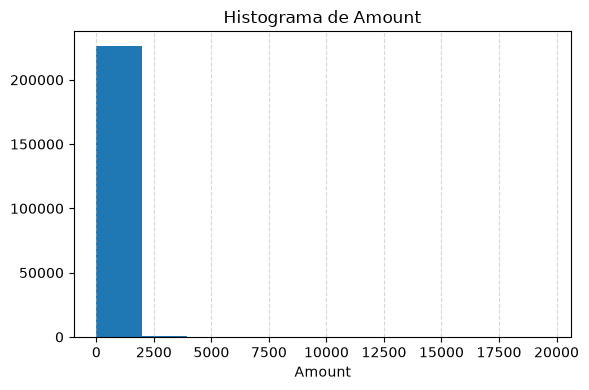

In [296]:
plt.figure(figsize=(6, 4))
plt.hist(df_plot["Amount"])

plt.title("Histograma de Amount")
plt.xlabel("Amount")
plt.grid(axis="x", linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

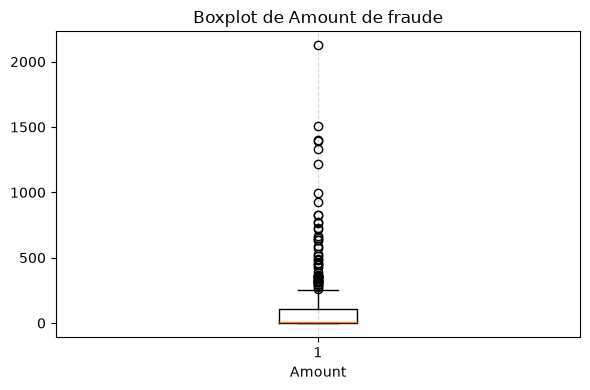

In [297]:
plt.figure(figsize=(6, 4))
plt.boxplot(df_plot[df_plot["Class"] == 1]["Amount"])

plt.title("Boxplot de Amount de fraude")
plt.xlabel("Amount")
plt.grid(axis="x", linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

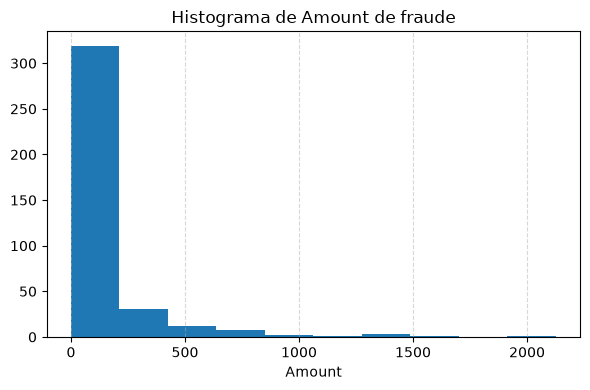

In [298]:
plt.figure(figsize=(6, 4))
plt.hist(df_plot[df_plot["Class"] == 1]["Amount"])

plt.title("Histograma de Amount de fraude")
plt.xlabel("Amount")
plt.grid(axis="x", linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

### Análisis de Horas

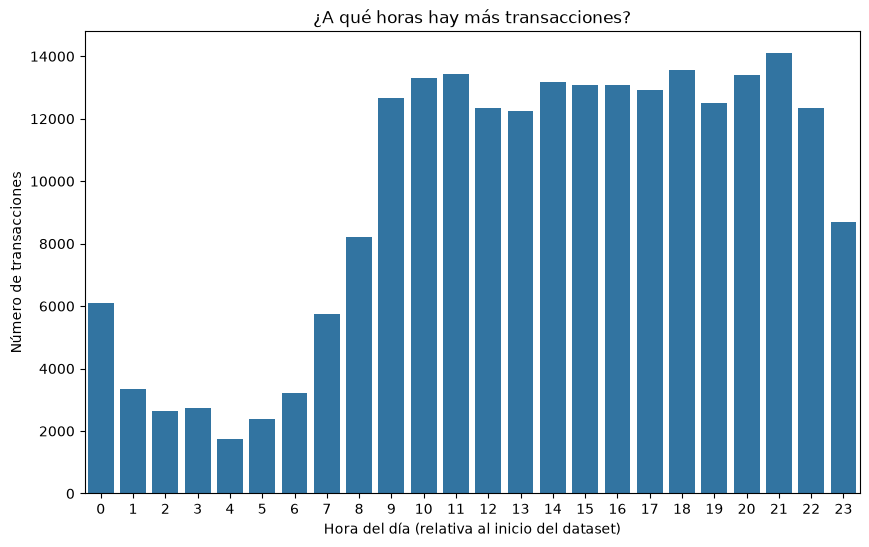

In [299]:
plt.figure(figsize=(10, 6))
sns.countplot(x="Hour", data=df_plot)
plt.title("¿A qué horas hay más transacciones?")
plt.xlabel("Hora del día (relativa al inicio del dataset)")
plt.ylabel("Número de transacciones")
plt.show()

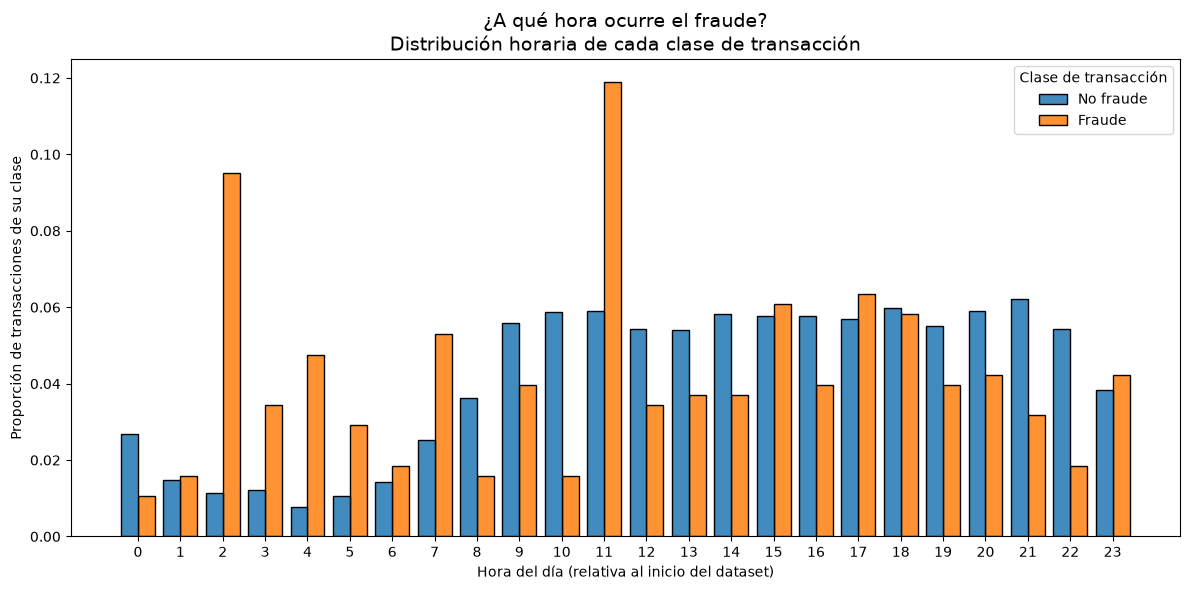

In [300]:
fig, ax = plt.subplots(figsize=(12, 6))

sns.histplot(
    data=df_plot,
    x="Hour",
    hue="Tipo",
    discrete=True,
    stat="proportion",
    common_norm=False,
    multiple="dodge",  
    shrink=0.8,       
    alpha=0.85,       
    ax=ax
)

ax.set_title("¿A qué hora ocurre el fraude?\nDistribución horaria de cada clase de transacción", fontsize=14)
ax.set_xlabel("Hora del día (relativa al inicio del dataset)")
ax.set_ylabel("Proporción de transacciones de su clase")
ax.set_xticks(range(24))
ax.get_legend().set_title("Clase de transacción")

plt.tight_layout()
plt.show()

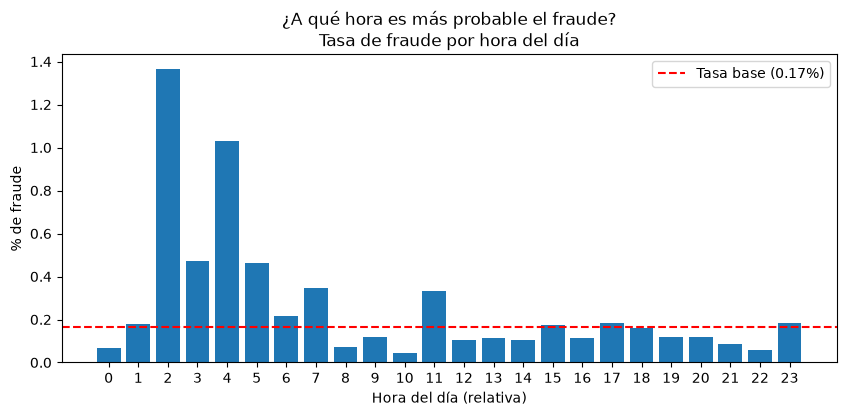

In [301]:
hourly = df_plot.groupby("Hour")["Class"].agg(total="count", fraudes="sum")
hourly["tasa_fraude_%"] = hourly["fraudes"] / hourly["total"] * 100

base = df_plot["Class"].mean() * 100

fig, ax = plt.subplots(figsize=(10, 4))
ax.bar(hourly.index, hourly["tasa_fraude_%"])
ax.axhline(base, color="red", ls="--", label=f"Tasa base ({base:.2f}%)")
plt.title("¿A qué hora es más probable el fraude?\nTasa de fraude por hora del día")
ax.set_xlabel("Hora del día (relativa)")
ax.set_ylabel("% de fraude")
ax.set_xticks(range(24))
ax.legend()
plt.show()

## Análisis Multivariante

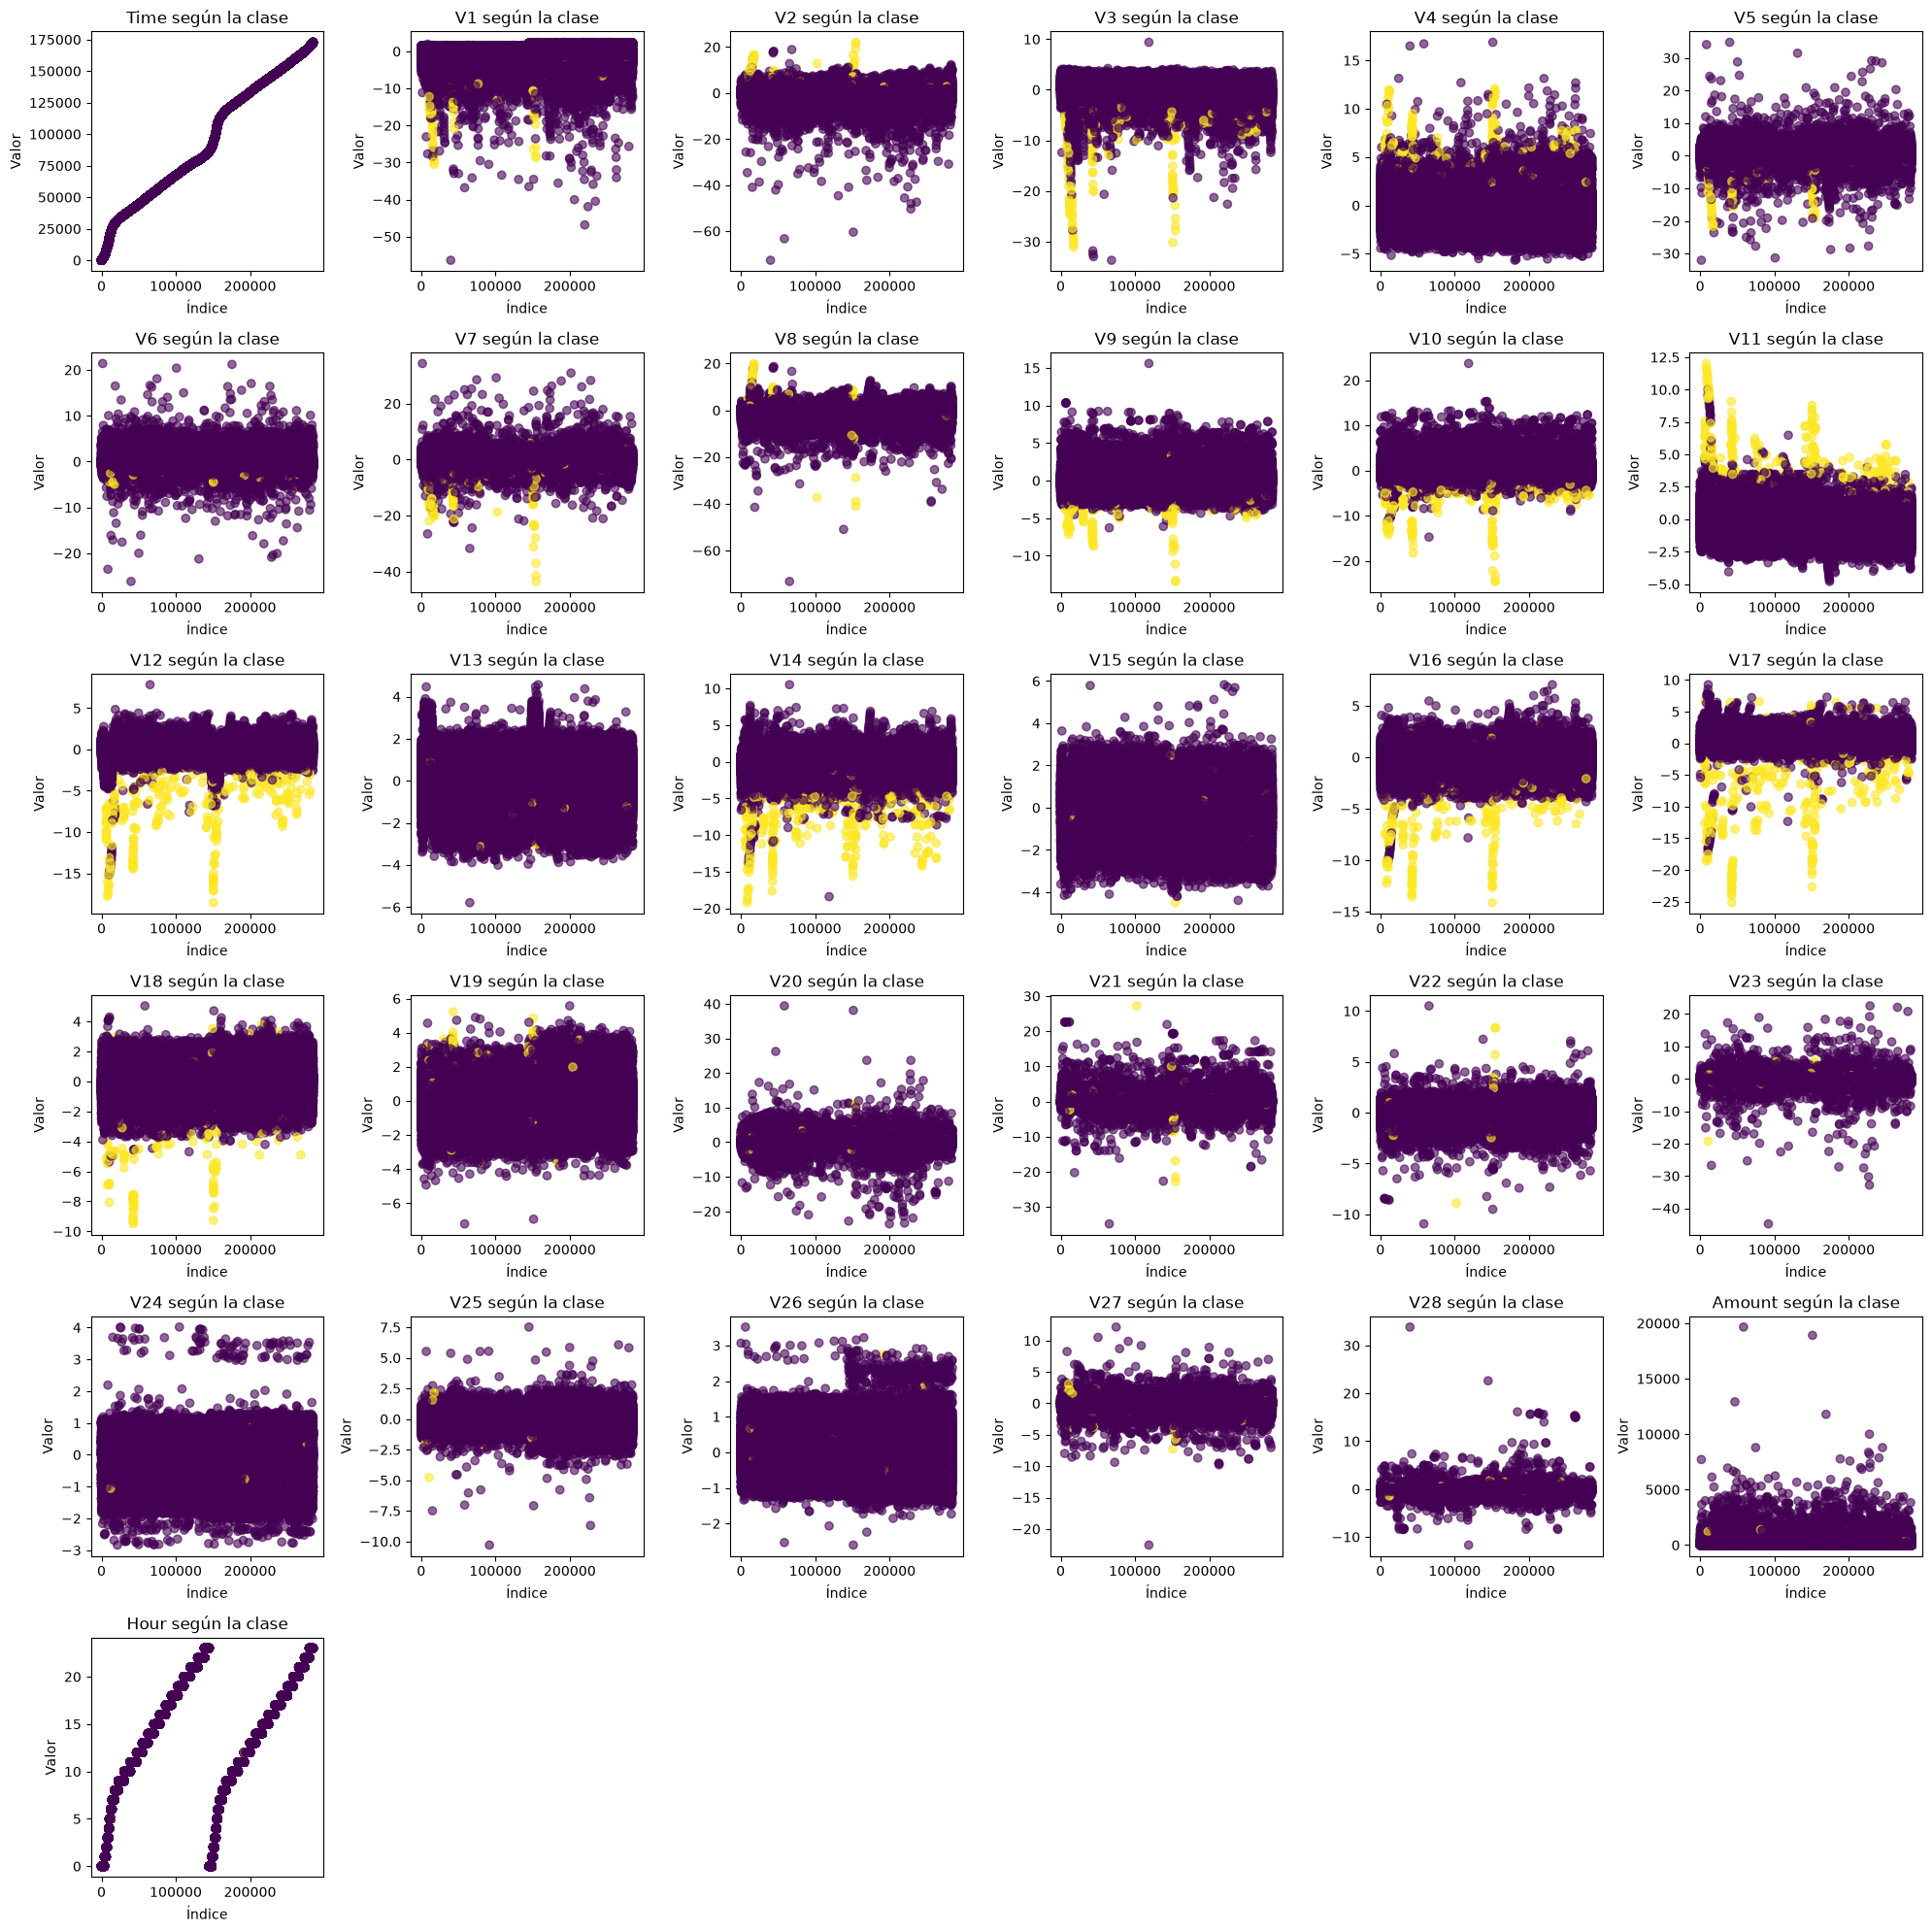

In [302]:
fig, axes = plt.subplots(6, 6, figsize=(20, 20))

for ax, col in zip(axes.flat, cols):
    ax.scatter(df_train.index, df_train[col], c=df_train["Class"], alpha=0.6)
    ax.set_title(f"{col} según la clase")
    ax.set_xlabel(f"Índice")
    ax.set_ylabel("Valor")

for ax in axes.flat[len(cols):]:
    ax.set_visible(False)

plt.tight_layout()
plt.show()

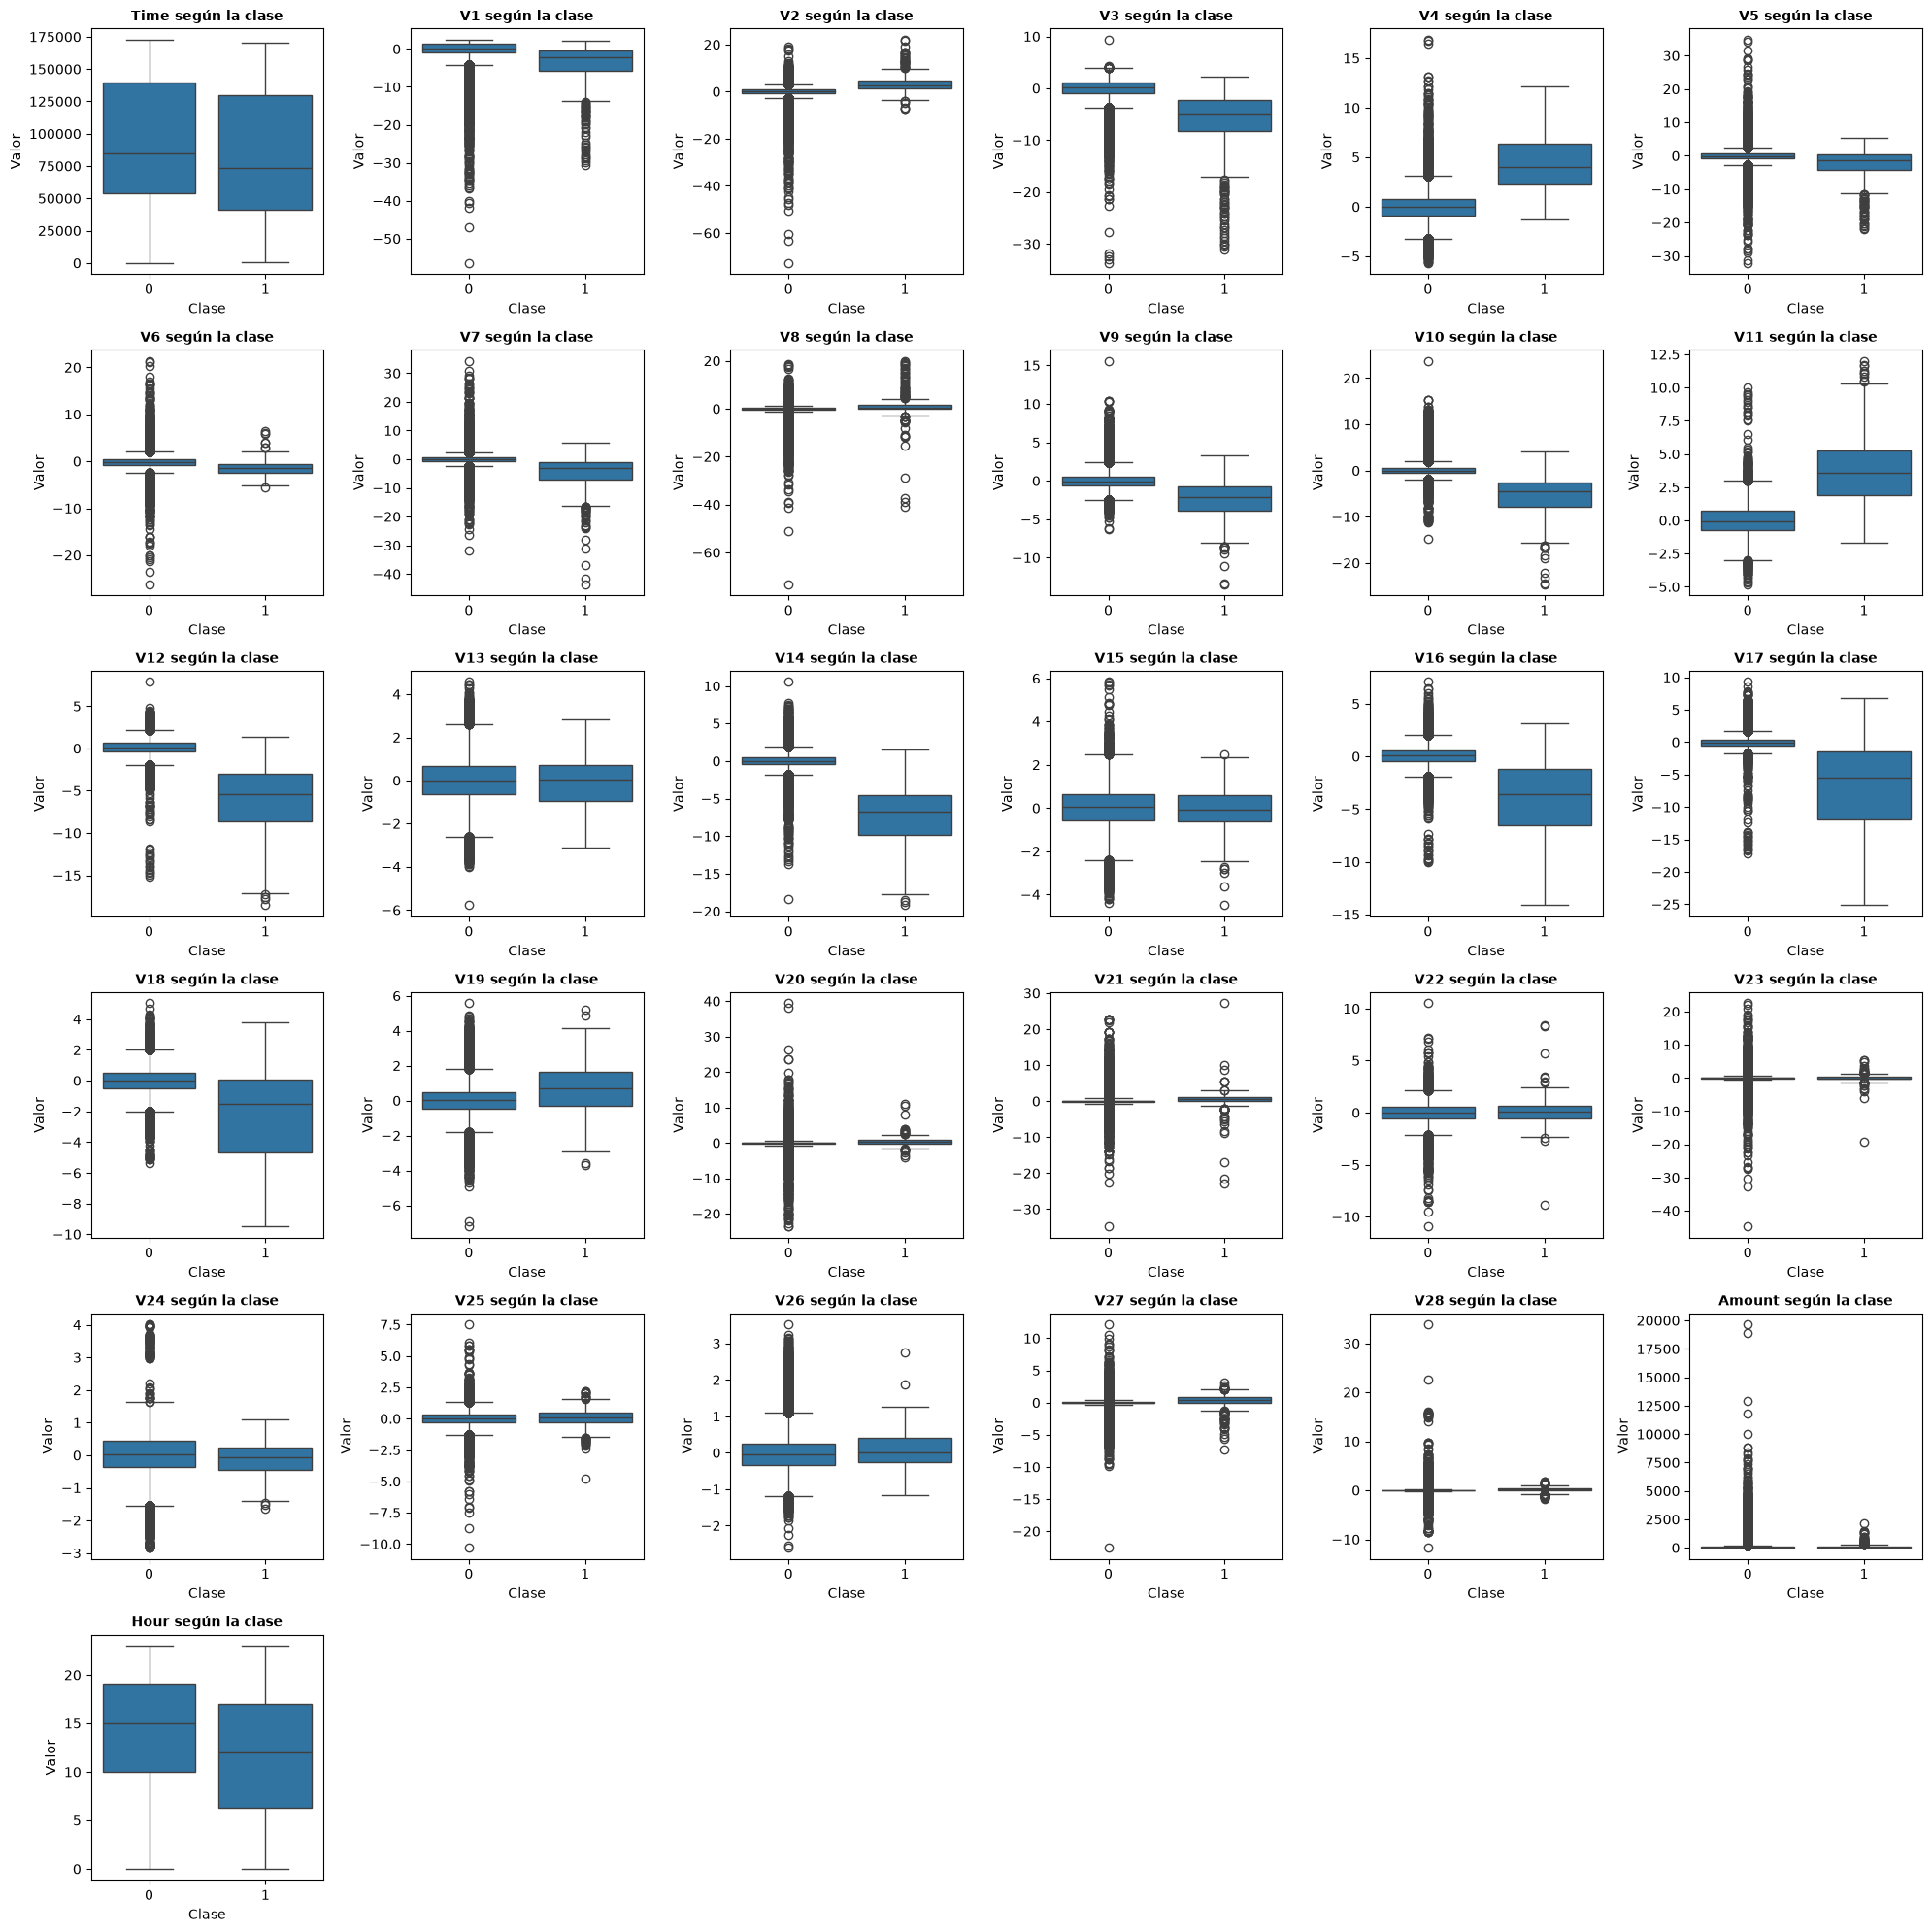

In [303]:
fig, axes = plt.subplots(6, 6, figsize=(20, 20))

for ax, col in zip(axes.flat, cols):
    sns.boxplot(data=df_train, x="Class", y=col, ax=ax)
    ax.set_title(f"{col} según la clase", fontsize=10, fontweight="bold")
    ax.set_xlabel("Clase")
    ax.set_ylabel("Valor")

for ax in axes.flat[len(cols):]:
    ax.set_visible(False)

plt.tight_layout()
plt.show()

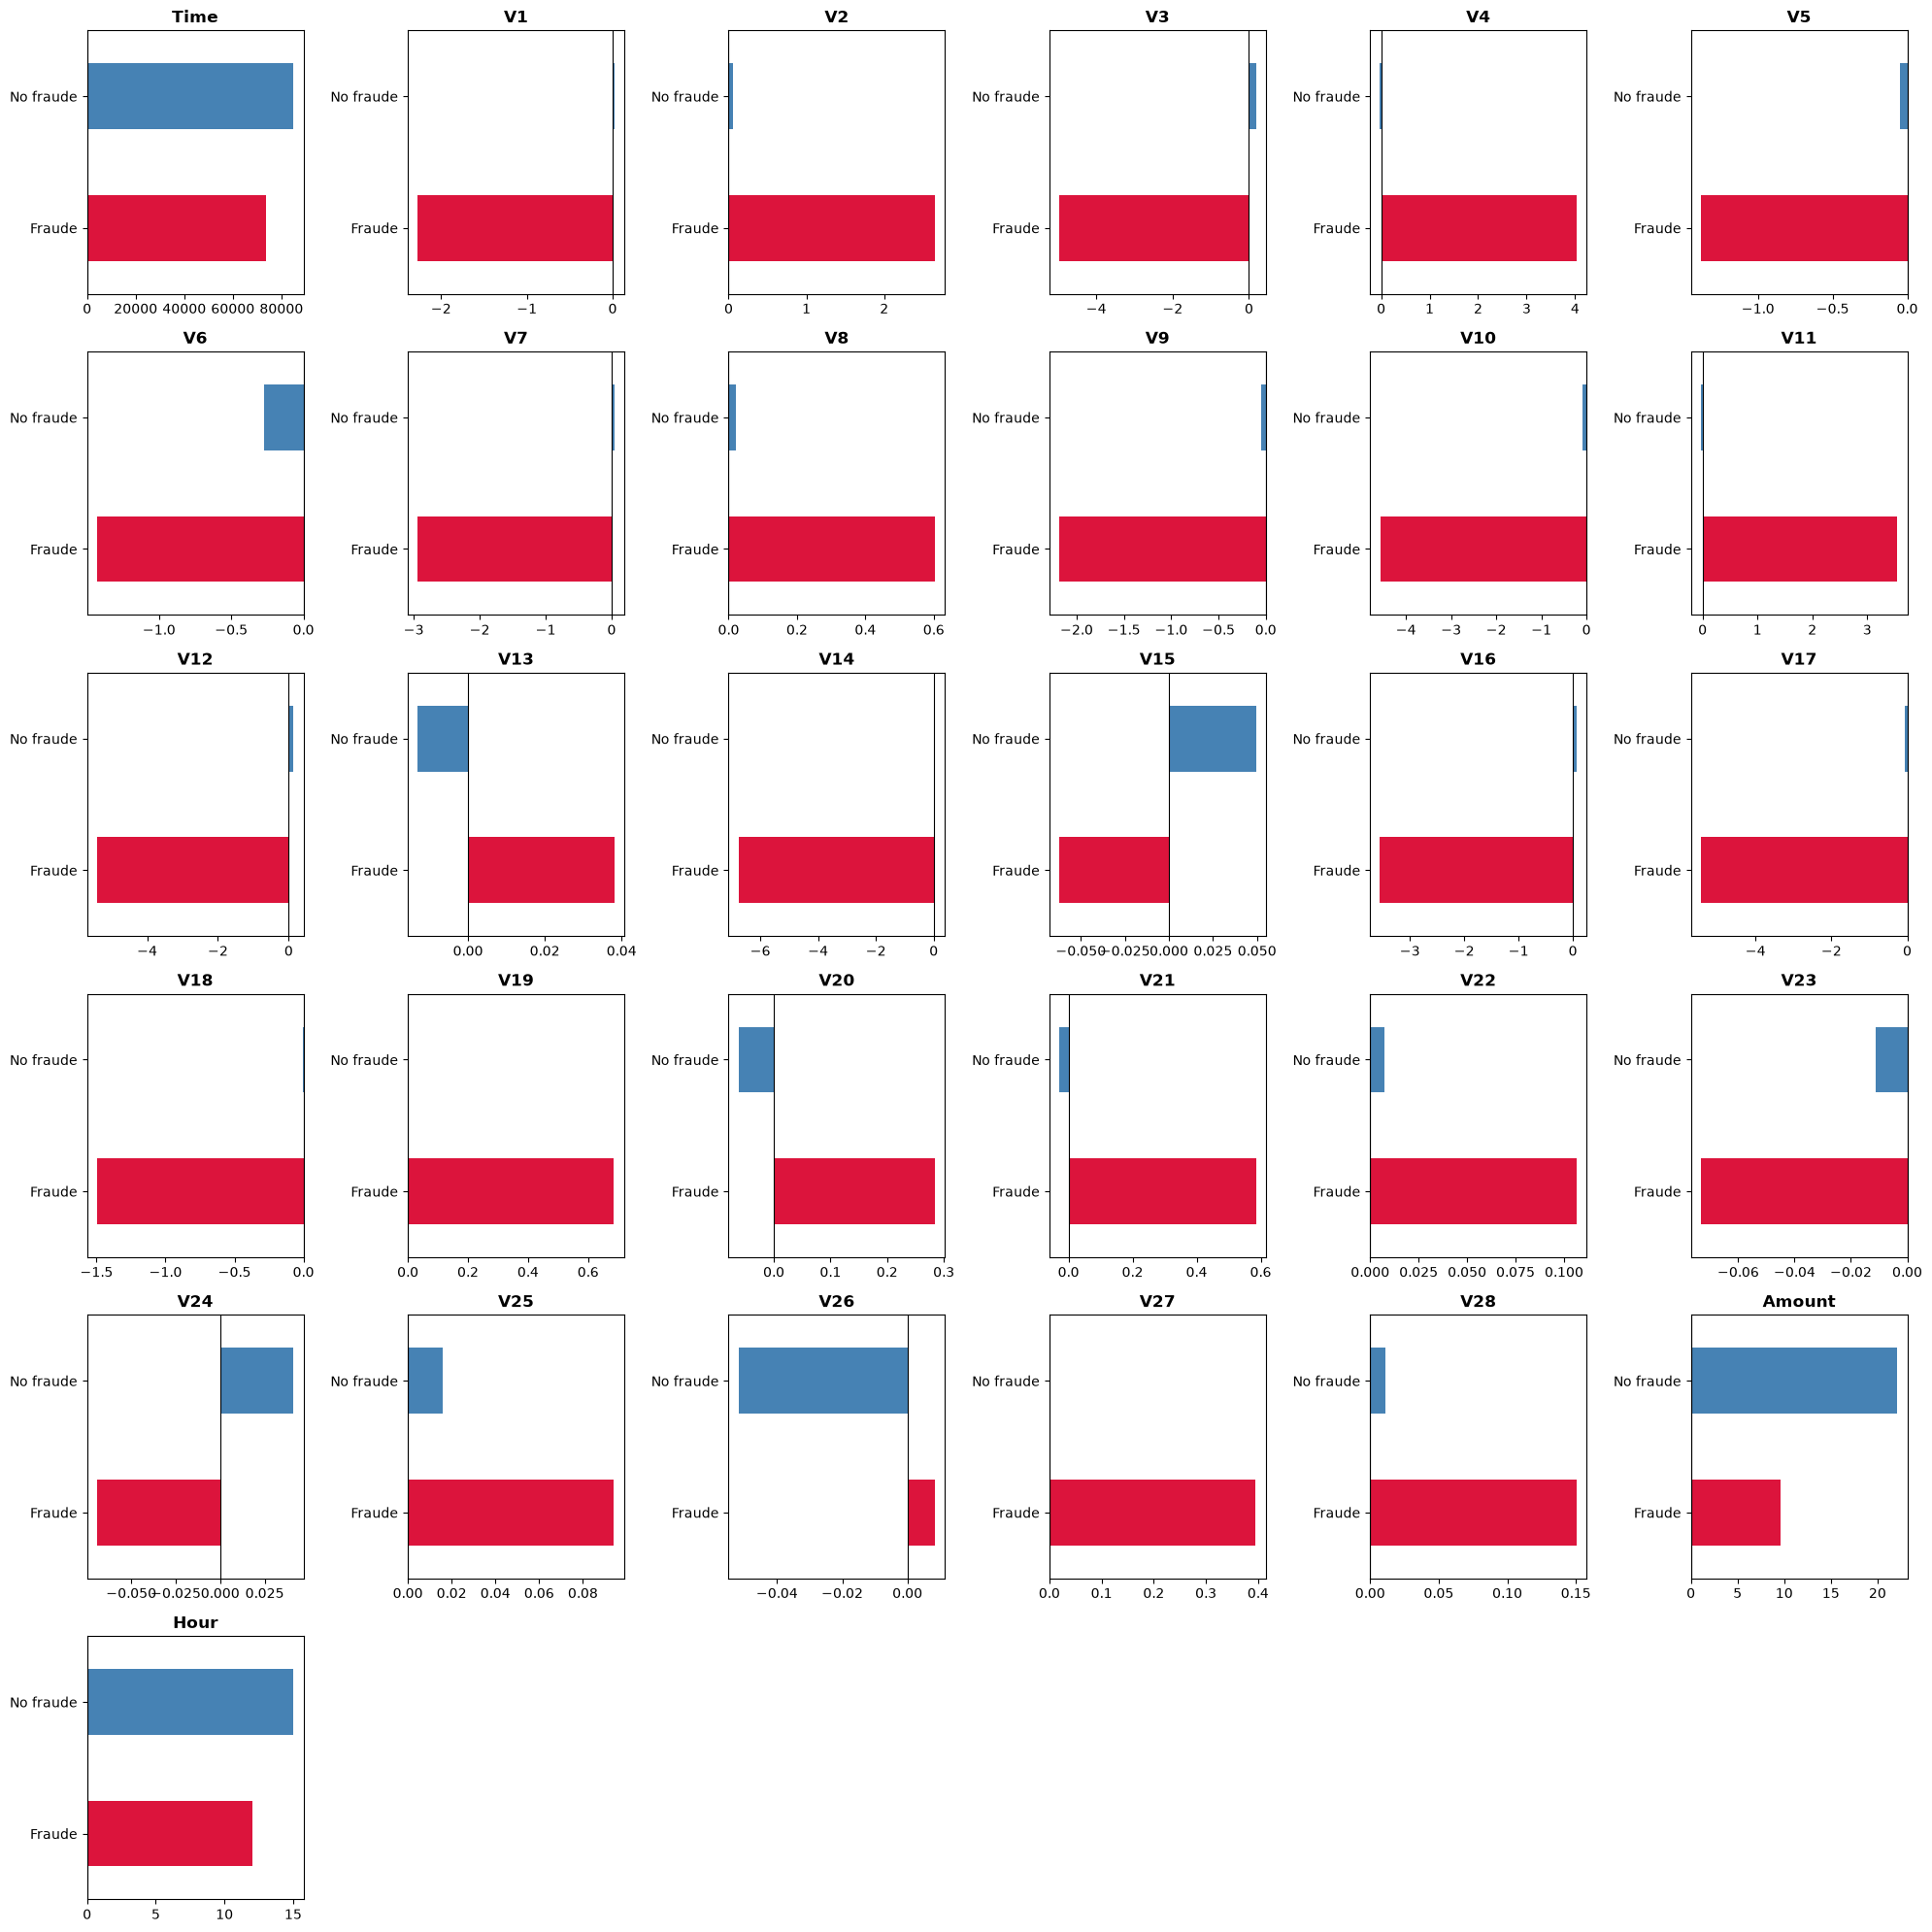

In [304]:
medianas = df_plot.groupby("Tipo")[cols].median()

fig, axes = plt.subplots(6, 6, figsize=(20, 20))

for ax, col in zip(axes.flat, cols):
    medianas[col].plot(kind="barh", ax=ax, color=["crimson", "steelblue"])
    ax.set_title(col, fontweight="bold")
    ax.set_ylabel("")
    ax.axvline(0, color="black", linewidth=0.8)

for ax in axes.flat[len(cols):]:
    ax.set_visible(False)

plt.tight_layout()
plt.show()

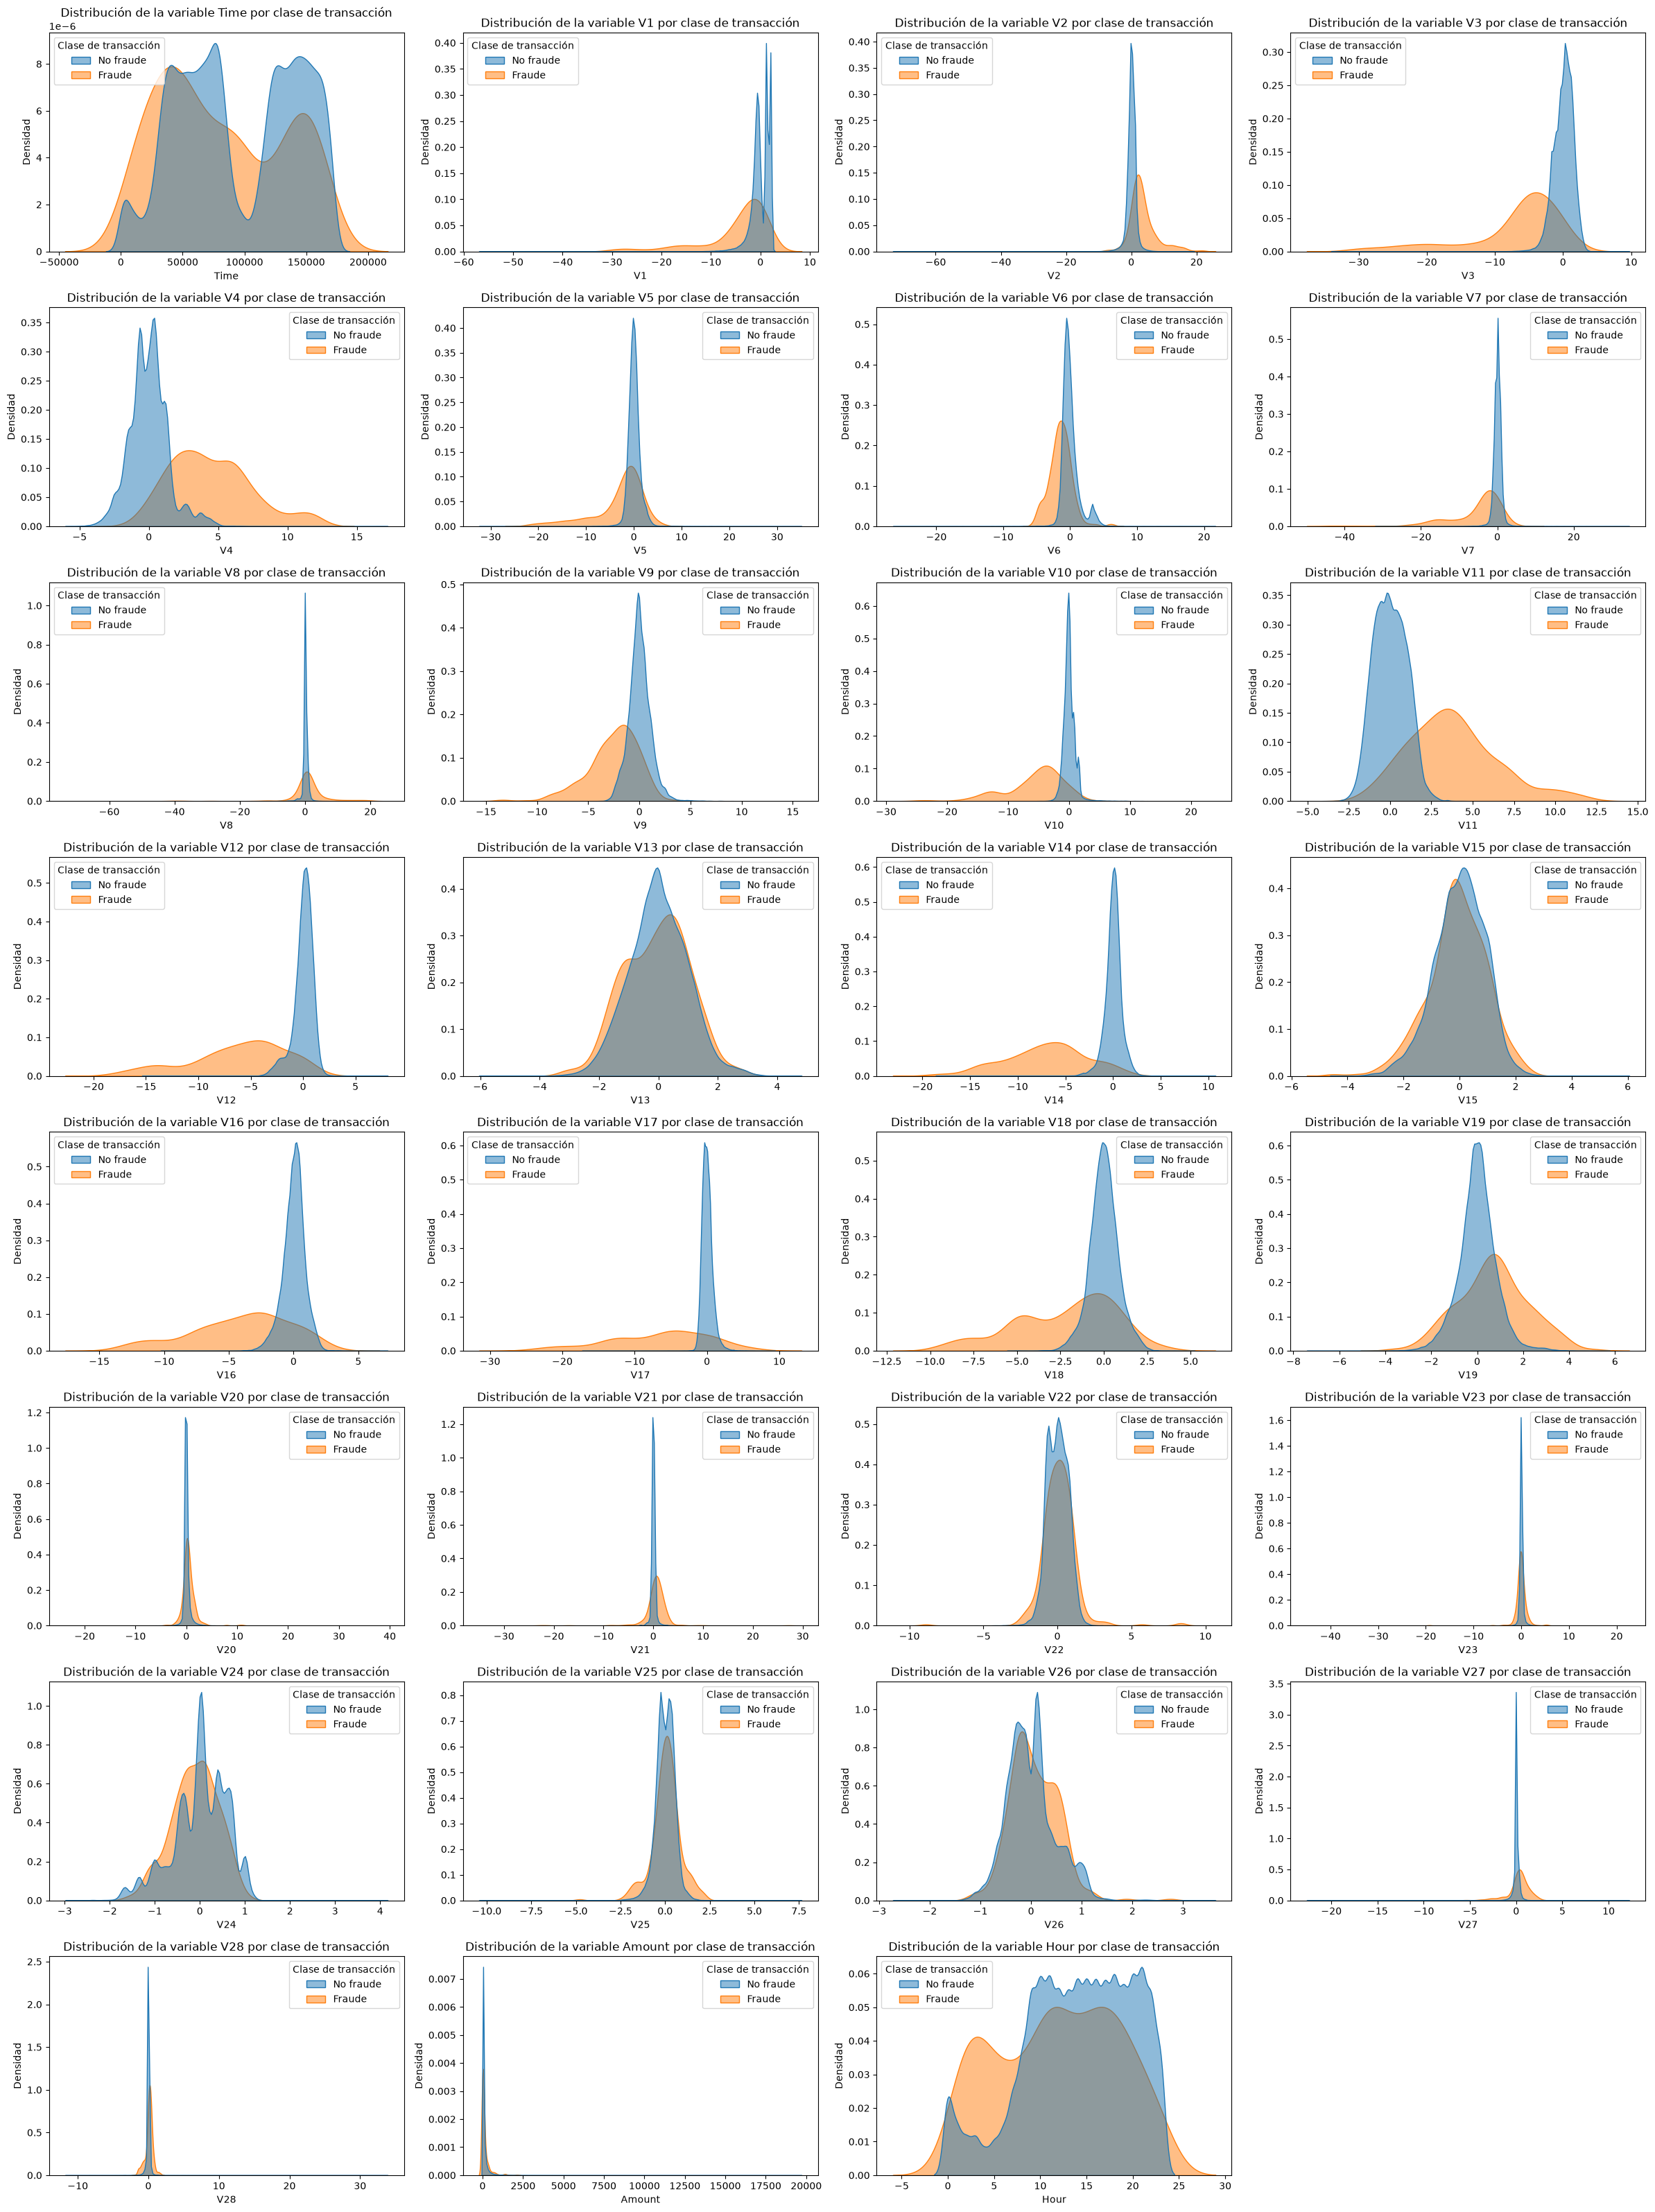

In [305]:
fig, axes = plt.subplots(8, 4, figsize=(24, 32))

for ax, col in zip(axes.flatten(), cols):
    sns.kdeplot(data=df_plot, x=col, hue='Tipo', fill=True, common_norm=False, alpha=0.5, ax=ax)
    ax.set_title(f'Distribución de la variable {col} por clase de transacción')
    ax.set_xlabel(col)
    ax.set_ylabel('Densidad')
    ax.get_legend().set_title('Clase de transacción')

for ax in axes.flat[len(cols):]:
    ax.set_visible(False)
    
fig.tight_layout()
plt.show()

### t-SNE

In [306]:
cols_v = []
for i in range(1, 29):
    cols_v.append(f"V{i}")

In [307]:
fraude = df_train[df_train["Class"] == 1]
normal = df_train[df_train["Class"] == 0].sample(n=5000, random_state=42)
muestra = pd.concat([normal, fraude])

In [308]:
tsne = TSNE(n_components=2, perplexity=30, init="pca", random_state=42)
emb = tsne.fit_transform(muestra[cols_v])

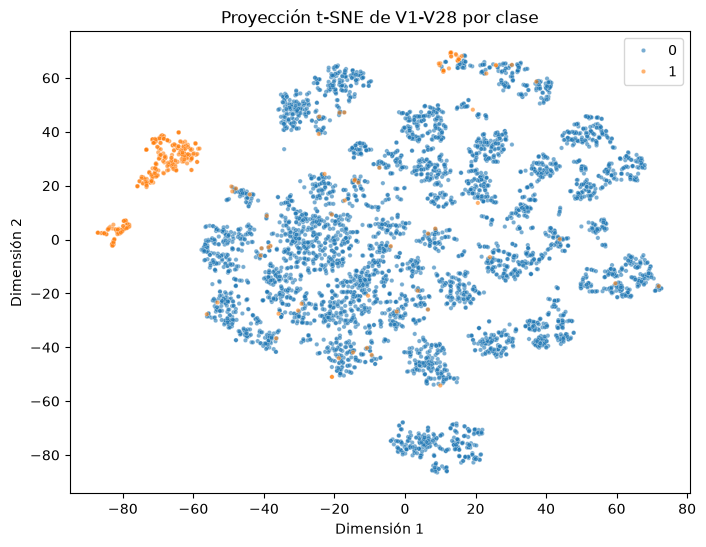

In [309]:
plt.figure(figsize=(8, 6))
sns.scatterplot(x=emb[:, 0], y=emb[:, 1], hue=muestra["Class"].values, s=10, alpha=0.6)
plt.title("Proyección t-SNE de V1-V28 por clase")
plt.xlabel("Dimensión 1")
plt.ylabel("Dimensión 2")
plt.show()

#### UMAP

c:\Users\bernu\anaconda3\envs\fraude_ml\Lib\site-packages\umap\umap_.py:4160: FutureWarning: compatibility_layout was not set, so UMAP is using the legacy (0.5.x) nearest-neighbor, initialization and layout pipeline. In a future release the default will change to compatibility_layout=False, which uses recursive initialization and the Adam optimizer and produces different embeddings. Set compatibility_layout=True to keep the current behavior and silence this warning, or compatibility_layout=False (or optimizer='adam') to adopt the new behavior now.
  self.fit(X, y, ensure_all_finite, **kwargs)
c:\Users\bernu\anaconda3\envs\fraude_ml\Lib\site-packages\umap\umap_.py:3099: UserWarning: n_jobs value -1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


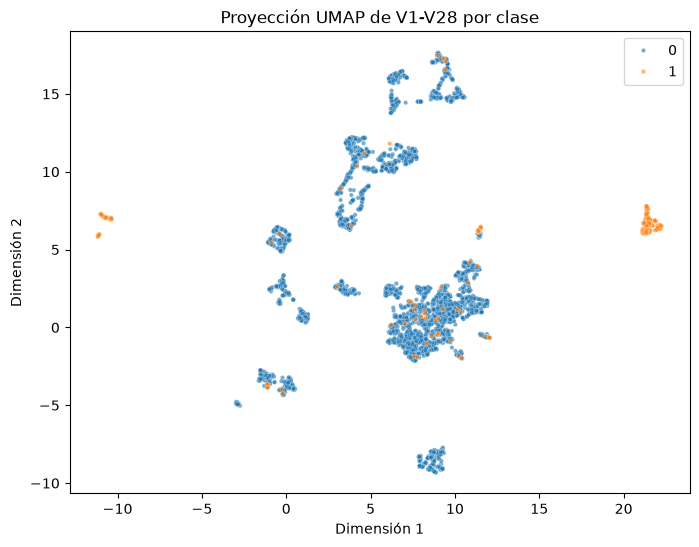

In [310]:
reducer = umap.UMAP(n_components=2, n_neighbors=15, min_dist=0.1, random_state=42)
emb_umap = reducer.fit_transform(muestra[cols_v])

plt.figure(figsize=(8, 6))
sns.scatterplot(x=emb_umap[:, 0], y=emb_umap[:, 1], hue=muestra["Class"].values, s=10, alpha=0.6)
plt.title("Proyección UMAP de V1-V28 por clase")
plt.xlabel("Dimensión 1")
plt.ylabel("Dimensión 2")
plt.show()

#### Poder discriminatorio de las variables

In [311]:
medias = df_plot.groupby('Class')[cols].mean().T.rename(columns={0: 'No Fraude', 1: 'Fraude'})
medias['Diferencia'] = medias['Fraude'] - medias['No Fraude']
medias['STD'] = df_plot[cols].std()
medias['Diferencia_std'] = (medias['Diferencia'] / medias['STD']).abs()
medias = medias.round(4).sort_values(by='Diferencia_std', ascending=False)
print(medias)

Class    No Fraude      Fraude  Diferencia         STD  Diferencia_std
V17         0.0104     -6.6202     -6.6306      0.8431          7.8644
V14         0.0101     -7.0495     -7.0597      0.9543          7.3978
V12         0.0104     -6.1881     -6.1984      0.9924          6.2461
V10         0.0071     -5.5634     -5.5705      1.0732          5.1905
V16         0.0081     -4.0699     -4.0780      0.8737          4.6677
V3          0.0138     -6.9679     -6.9817      1.5073          4.6320
V7          0.0104     -5.3167     -5.3271      1.2002          4.4386
V11        -0.0062      3.7940      3.8002      1.0187          3.7306
V4         -0.0095      4.4983      4.5079      1.4170          3.1814
V18         0.0059     -2.1935     -2.1994      0.8373          2.6266
V1          0.0128     -4.6481     -4.6609      1.9473          2.3935
V9          0.0014     -2.5671     -2.5685      1.0941          2.3477
V5          0.0100     -3.0563     -3.0663      1.3596          2.2553
V2    

In [312]:
mediana = df_train.groupby('Class')[cols].median().T.rename(columns={0: 'No Fraude', 1: 'Fraude'})
mediana['Diferencia'] = mediana['Fraude'] - mediana['No Fraude']
mediana['STD'] = df_plot[cols].std()
mediana['Diferencia_std'] = (mediana['Diferencia'] / mediana['STD']).abs()
mediana = mediana.round(4).sort_values(by='Diferencia_std', ascending=False)
print(mediana)

Class    No Fraude      Fraude  Diferencia         STD  Diferencia_std
V14         0.0500     -6.7544     -6.8045      0.9543          7.1304
V17        -0.0648     -5.4309     -5.3661      0.8431          6.3646
V12         0.1397     -5.4182     -5.5578      0.9924          5.6006
V10        -0.0926     -4.5653     -4.4726      1.0732          4.1675
V16         0.0694     -3.5498     -3.6192      0.8737          4.1426
V11        -0.0337      3.5504      3.5840      1.0187          3.5184
V3          0.1806     -4.9696     -5.1502      1.5073          3.4169
V4         -0.0243      4.0322      4.0565      1.4170          2.8628
V7          0.0417     -2.9398     -2.9814      1.2002          2.4842
V9         -0.0523     -2.1791     -2.1268      1.0941          1.9440
V18        -0.0004     -1.4935     -1.4931      0.8373          1.7831
V2          0.0622      2.6486      2.5863      1.6496          1.5678
V1          0.0203     -2.2721     -2.2924      1.9473          1.1772
V27   

### Correlación

#### Pearson

In [313]:
corr_pr = df_train.corr()

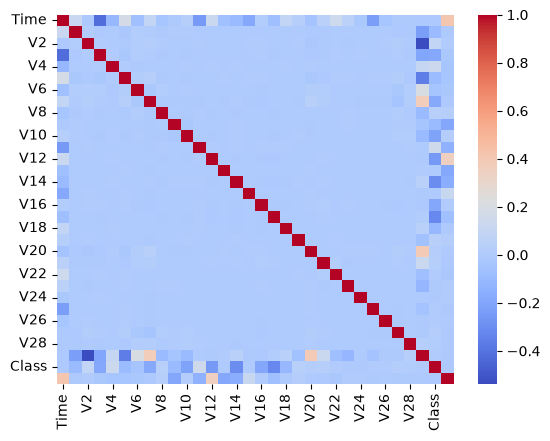

In [314]:
sns.heatmap(corr_pr, cmap='coolwarm')
plt.show()

In [315]:
corr_pr_fraude = df_train[df_train['Class']==1].corr()

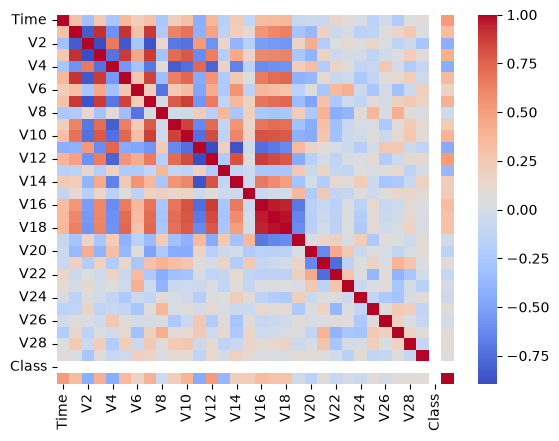

In [316]:
sns.heatmap(corr_pr_fraude, cmap='coolwarm')
plt.show()

#### Spearman

In [317]:
corr_sp = df_train.corr(method = "spearman")

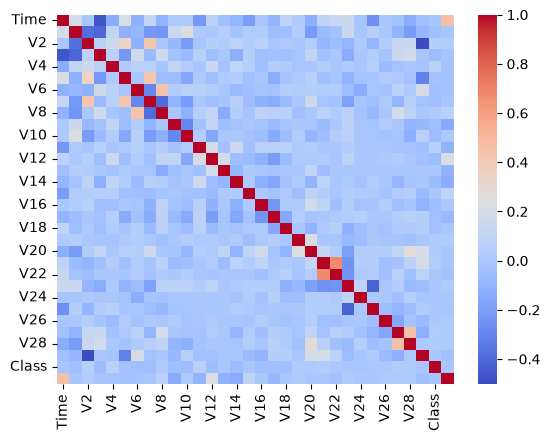

In [318]:
sns.heatmap(corr_sp, cmap='coolwarm')
plt.show()

In [319]:
corr_sp_fraude = df_train[df_train['Class']==1].corr(method = "spearman")

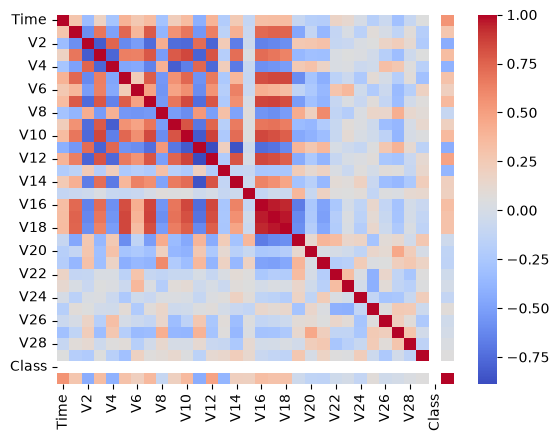

In [320]:
sns.heatmap(corr_sp_fraude, cmap='coolwarm')
plt.show()

#### Área bajo la curva (AUC)

In [321]:
resultados = {}

for c in cols:
    resultados[c] = roc_auc_score(df_train['Class'], df_train[c])

auc = pd.Series(resultados).sort_values(ascending=False)

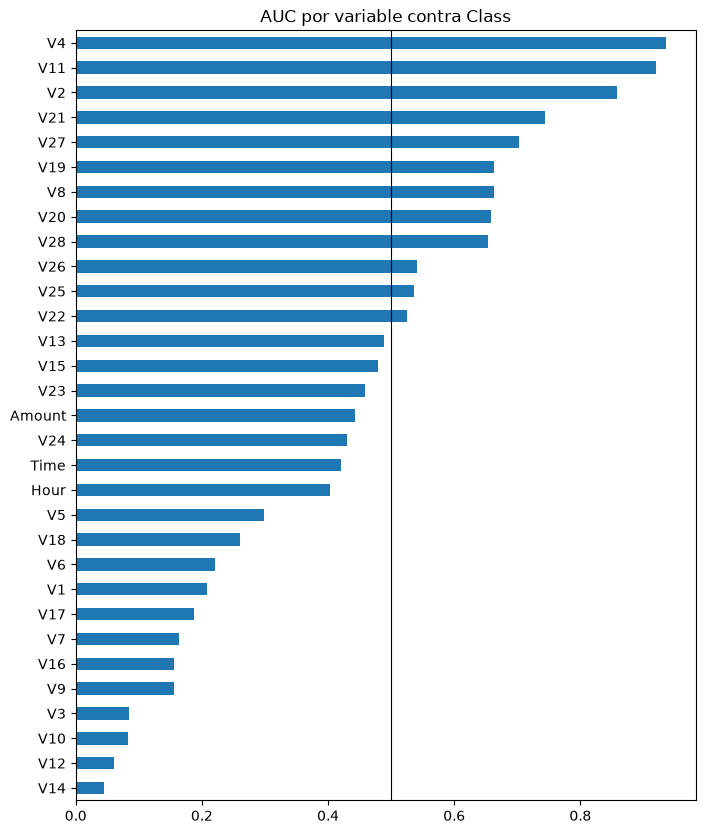

In [322]:
auc.sort_values().plot.barh(figsize=(8, 10))
plt.axvline(0.5, color="black", lw=0.8)
plt.title("AUC por variable contra Class")
plt.show()

In [323]:
tabla_auc = pd.DataFrame({
    'AUC': auc,
    'Poder': np.maximum(auc, 1 - auc),
}).sort_values('Poder', ascending=False)

display(tabla_auc)

,AUC,Poder
V14,0.044575,0.955425
V12,0.061120,0.938880
V4,0.936090,0.936090
V11,0.919791,0.919791
V10,0.083367,0.916633
V3,0.083875,0.916125
V2,0.858452,0.858452
V9,0.155931,0.844069
V16,0.156332,0.843668
V7,0.163567,0.836433


### Ranking de Feautures

In [324]:
comp = pd.DataFrame({
    'dif_mean_std': medias['Diferencia_std'],
    'dif_median_std': mediana['Diferencia_std'],
    'AUC': auc
})

fuerza = comp[['dif_mean_std', 'dif_median_std']].abs()
fuerza['AUC'] = np.maximum(comp['AUC'], 1 - comp['AUC'])

ranks = fuerza.rank(ascending=False, method='min').add_prefix('rank_')

comp = comp.join(ranks)
comp['rank_promedio'] = ranks.mean(axis=1)
comp['rank_final'] = comp['rank_promedio'].rank(method='min').astype(int)
comp = comp.sort_values('rank_promedio')

display(comp.round(4))

,dif_mean_std,dif_median_std,AUC,rank_dif_mean_std,rank_dif_median_std,rank_AUC,rank_promedio,rank_final
V14,7.3978,7.1304,0.0446,2.0,1.0,1.0,1.3333,1
V12,6.2461,5.6006,0.0611,3.0,3.0,2.0,2.6667,2
V10,5.1905,4.1675,0.0834,4.0,4.0,5.0,4.3333,3
V17,7.8644,6.3646,0.1868,1.0,2.0,11.0,4.6667,4
V11,3.7306,3.5184,0.9198,8.0,6.0,4.0,6.0000,5
V16,4.6677,4.1426,0.1563,5.0,5.0,9.0,6.3333,6
V3,4.6320,3.4169,0.0839,6.0,7.0,6.0,6.3333,6
V4,3.1814,2.8628,0.9361,9.0,8.0,3.0,6.6667,8
V7,4.4386,2.4842,0.1636,7.0,9.0,10.0,8.6667,9
V9,2.3477,1.9440,0.1559,12.0,10.0,8.0,10.0000,10


#### Visualización del top de las variables con más poder discriminador

In [325]:
ranking = comp.sort_values('rank_promedio')

promedios = ranking['rank_promedio']
saltos = promedios.diff()

k_elegido = saltos.reset_index(drop=True).idxmax()

top_lista = ranking.index[:k_elegido].tolist()
top_5 = top_lista[:5]

print("Corte elegido:", k_elegido)
print("Variables seleccionadas:", top_lista)
print("Top 5:", top_5)

Corte elegido: 13
Variables seleccionadas: ['V14', 'V12', 'V10', 'V17', 'V11', 'V16', 'V3', 'V4', 'V7', 'V9', 'V2', 'V1', 'V18']
Top 5: ['V14', 'V12', 'V10', 'V17', 'V11']


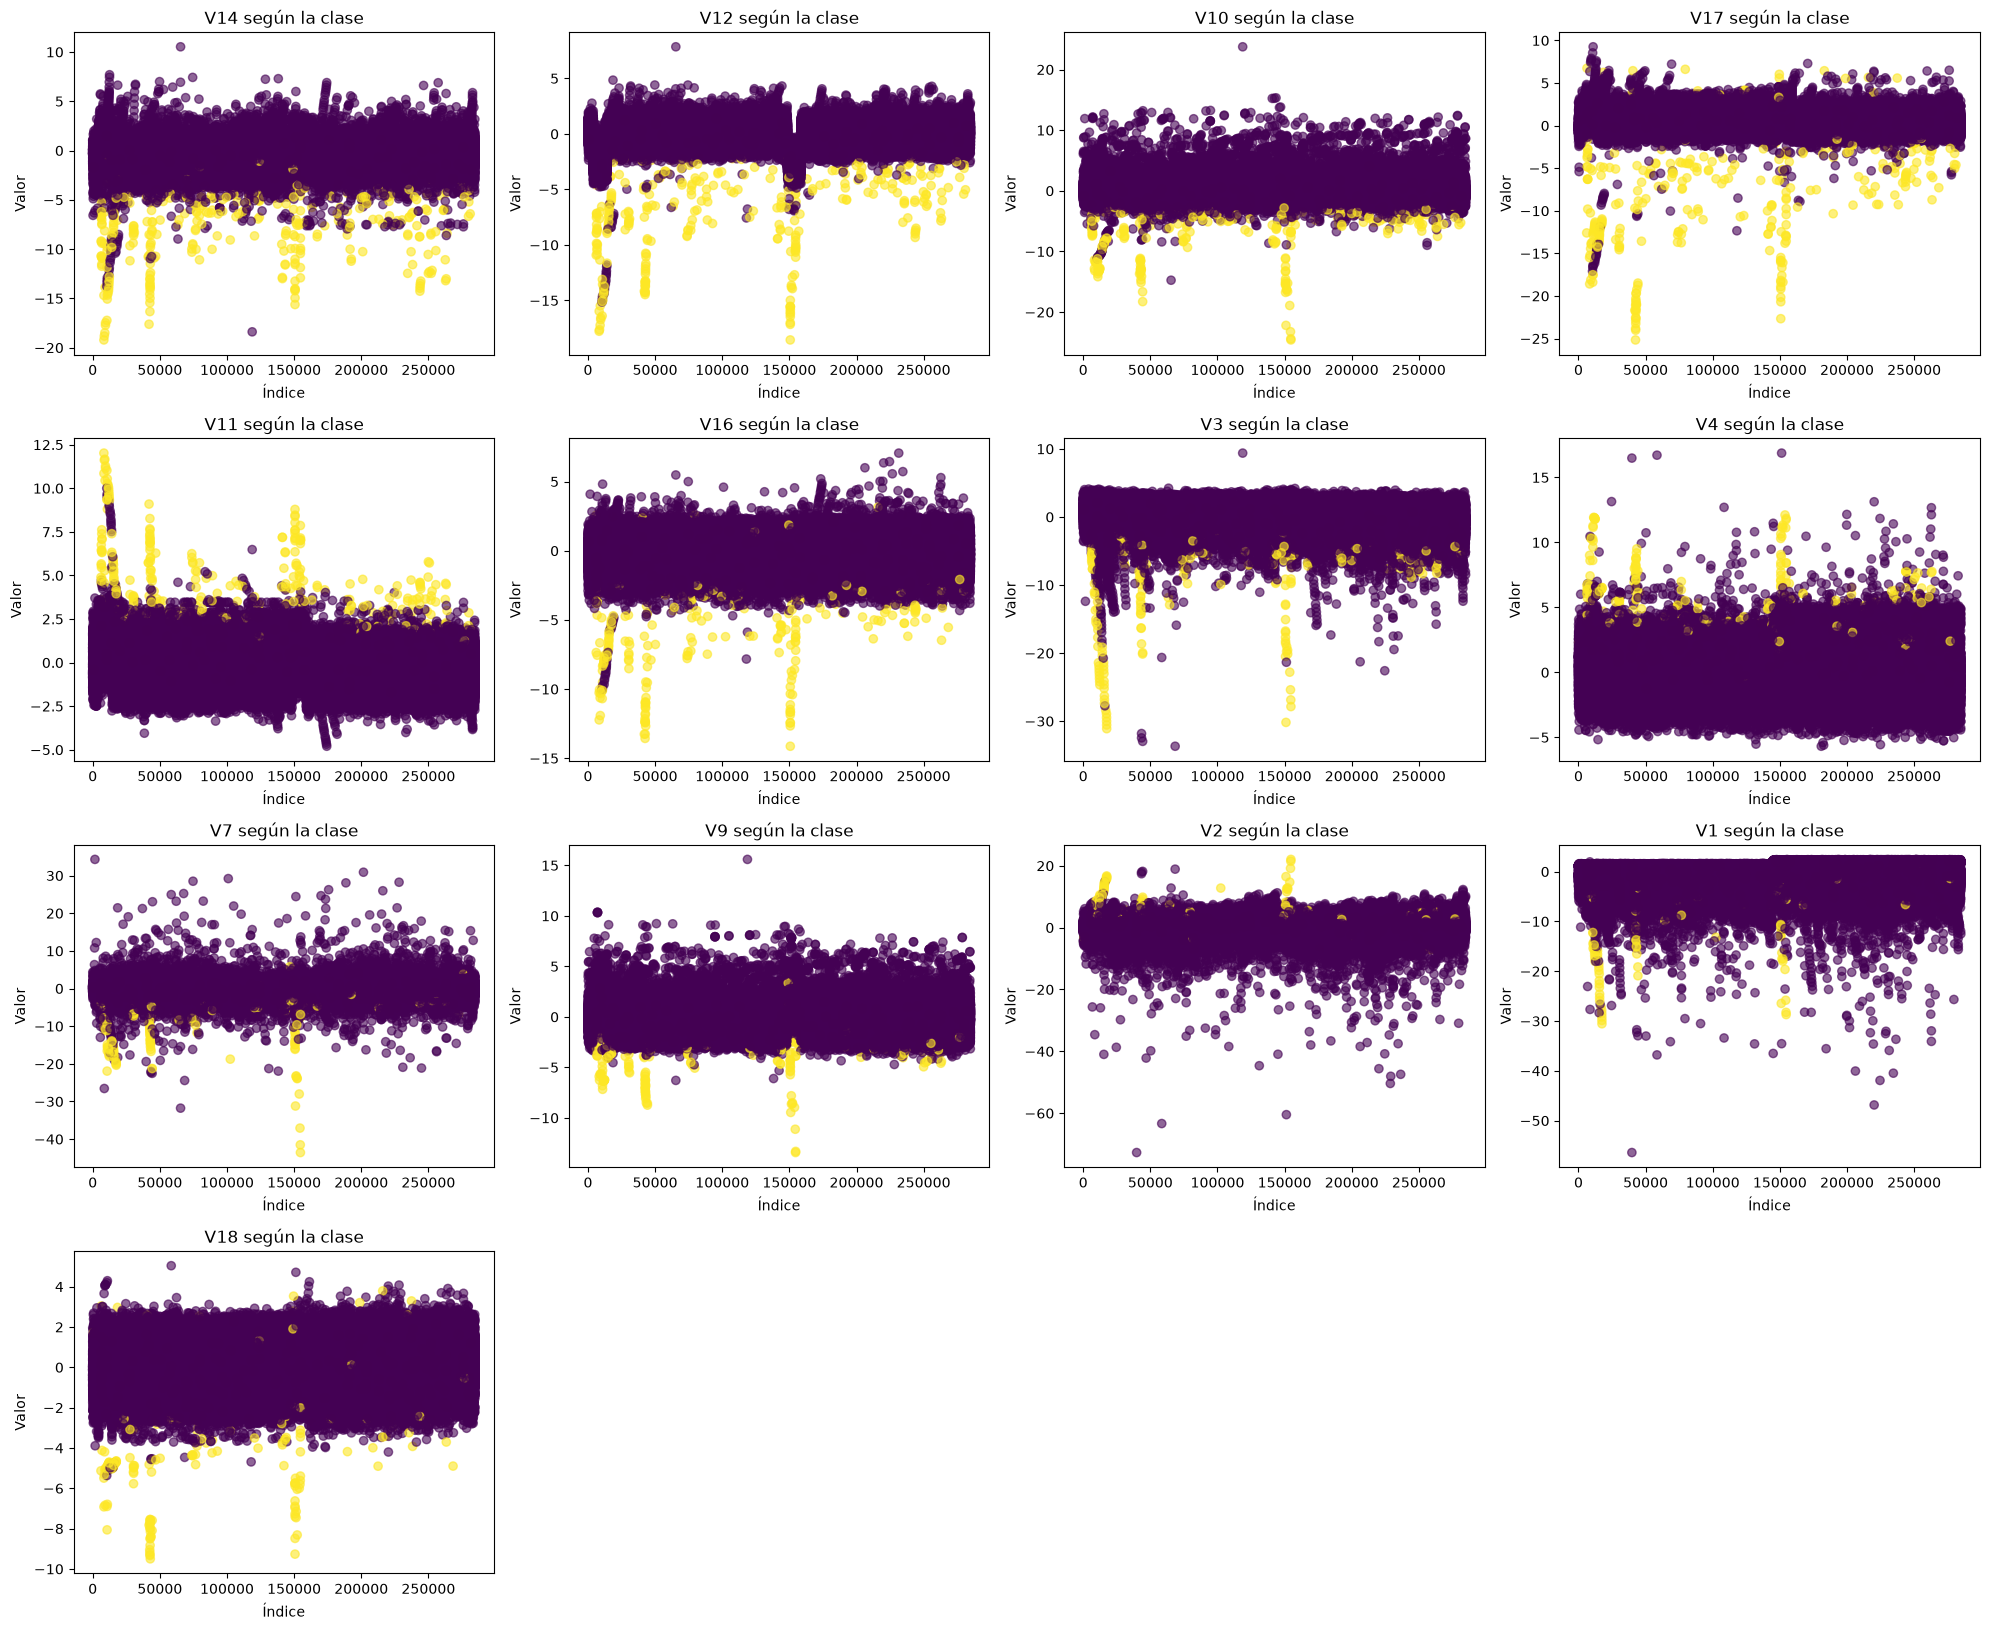

In [326]:
fig, axes = plt.subplots(5, 4, figsize=(20, 20))

for ax, col in zip(axes.flat, top_lista):
    ax.scatter(df_train.index, df_train[col], c=df_train["Class"], alpha=0.6)
    ax.set_title(f"{col} según la clase")
    ax.set_xlabel(f"Índice")
    ax.set_ylabel("Valor")

for ax in axes.flat[len(top_lista):]:
    ax.set_visible(False)

plt.tight_layout()
plt.show()

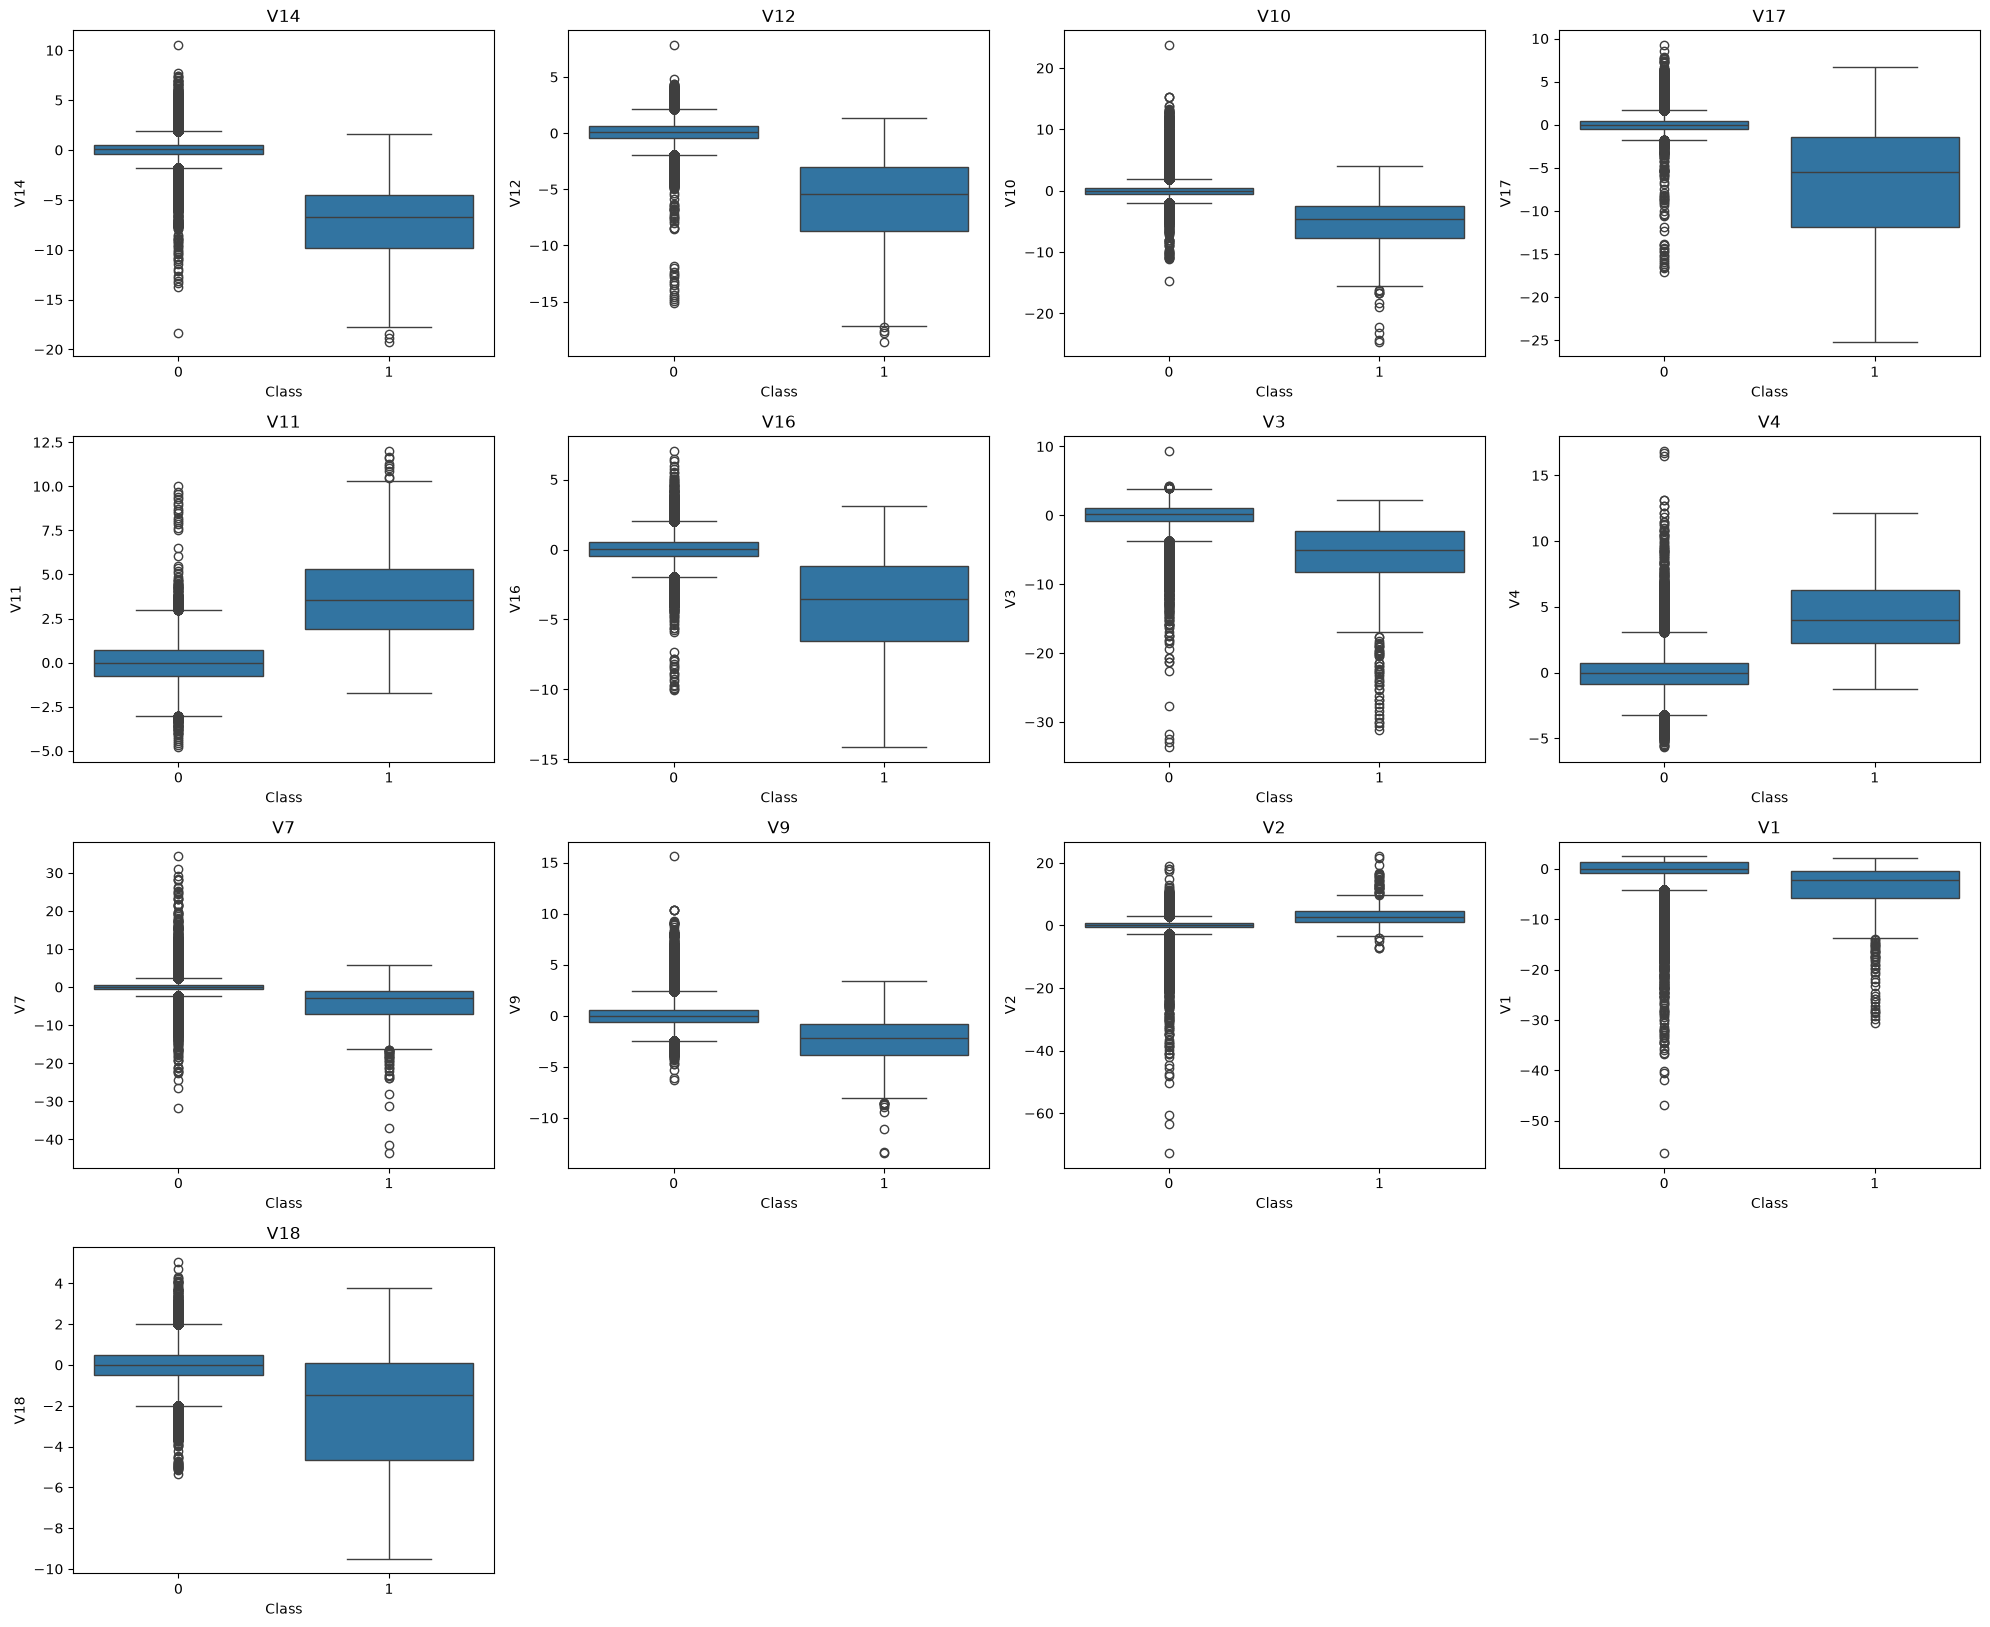

In [327]:
fig, axes = plt.subplots(5, 4, figsize=(20, 20))
for ax, col in zip(axes.ravel(), top_lista):
    sns.boxplot(data=df_train, x='Class', y=col, ax=ax)
    ax.set_title(col)

for ax in axes.flat[len(top_lista):]:
    ax.set_visible(False)
    
plt.tight_layout()
plt.show()

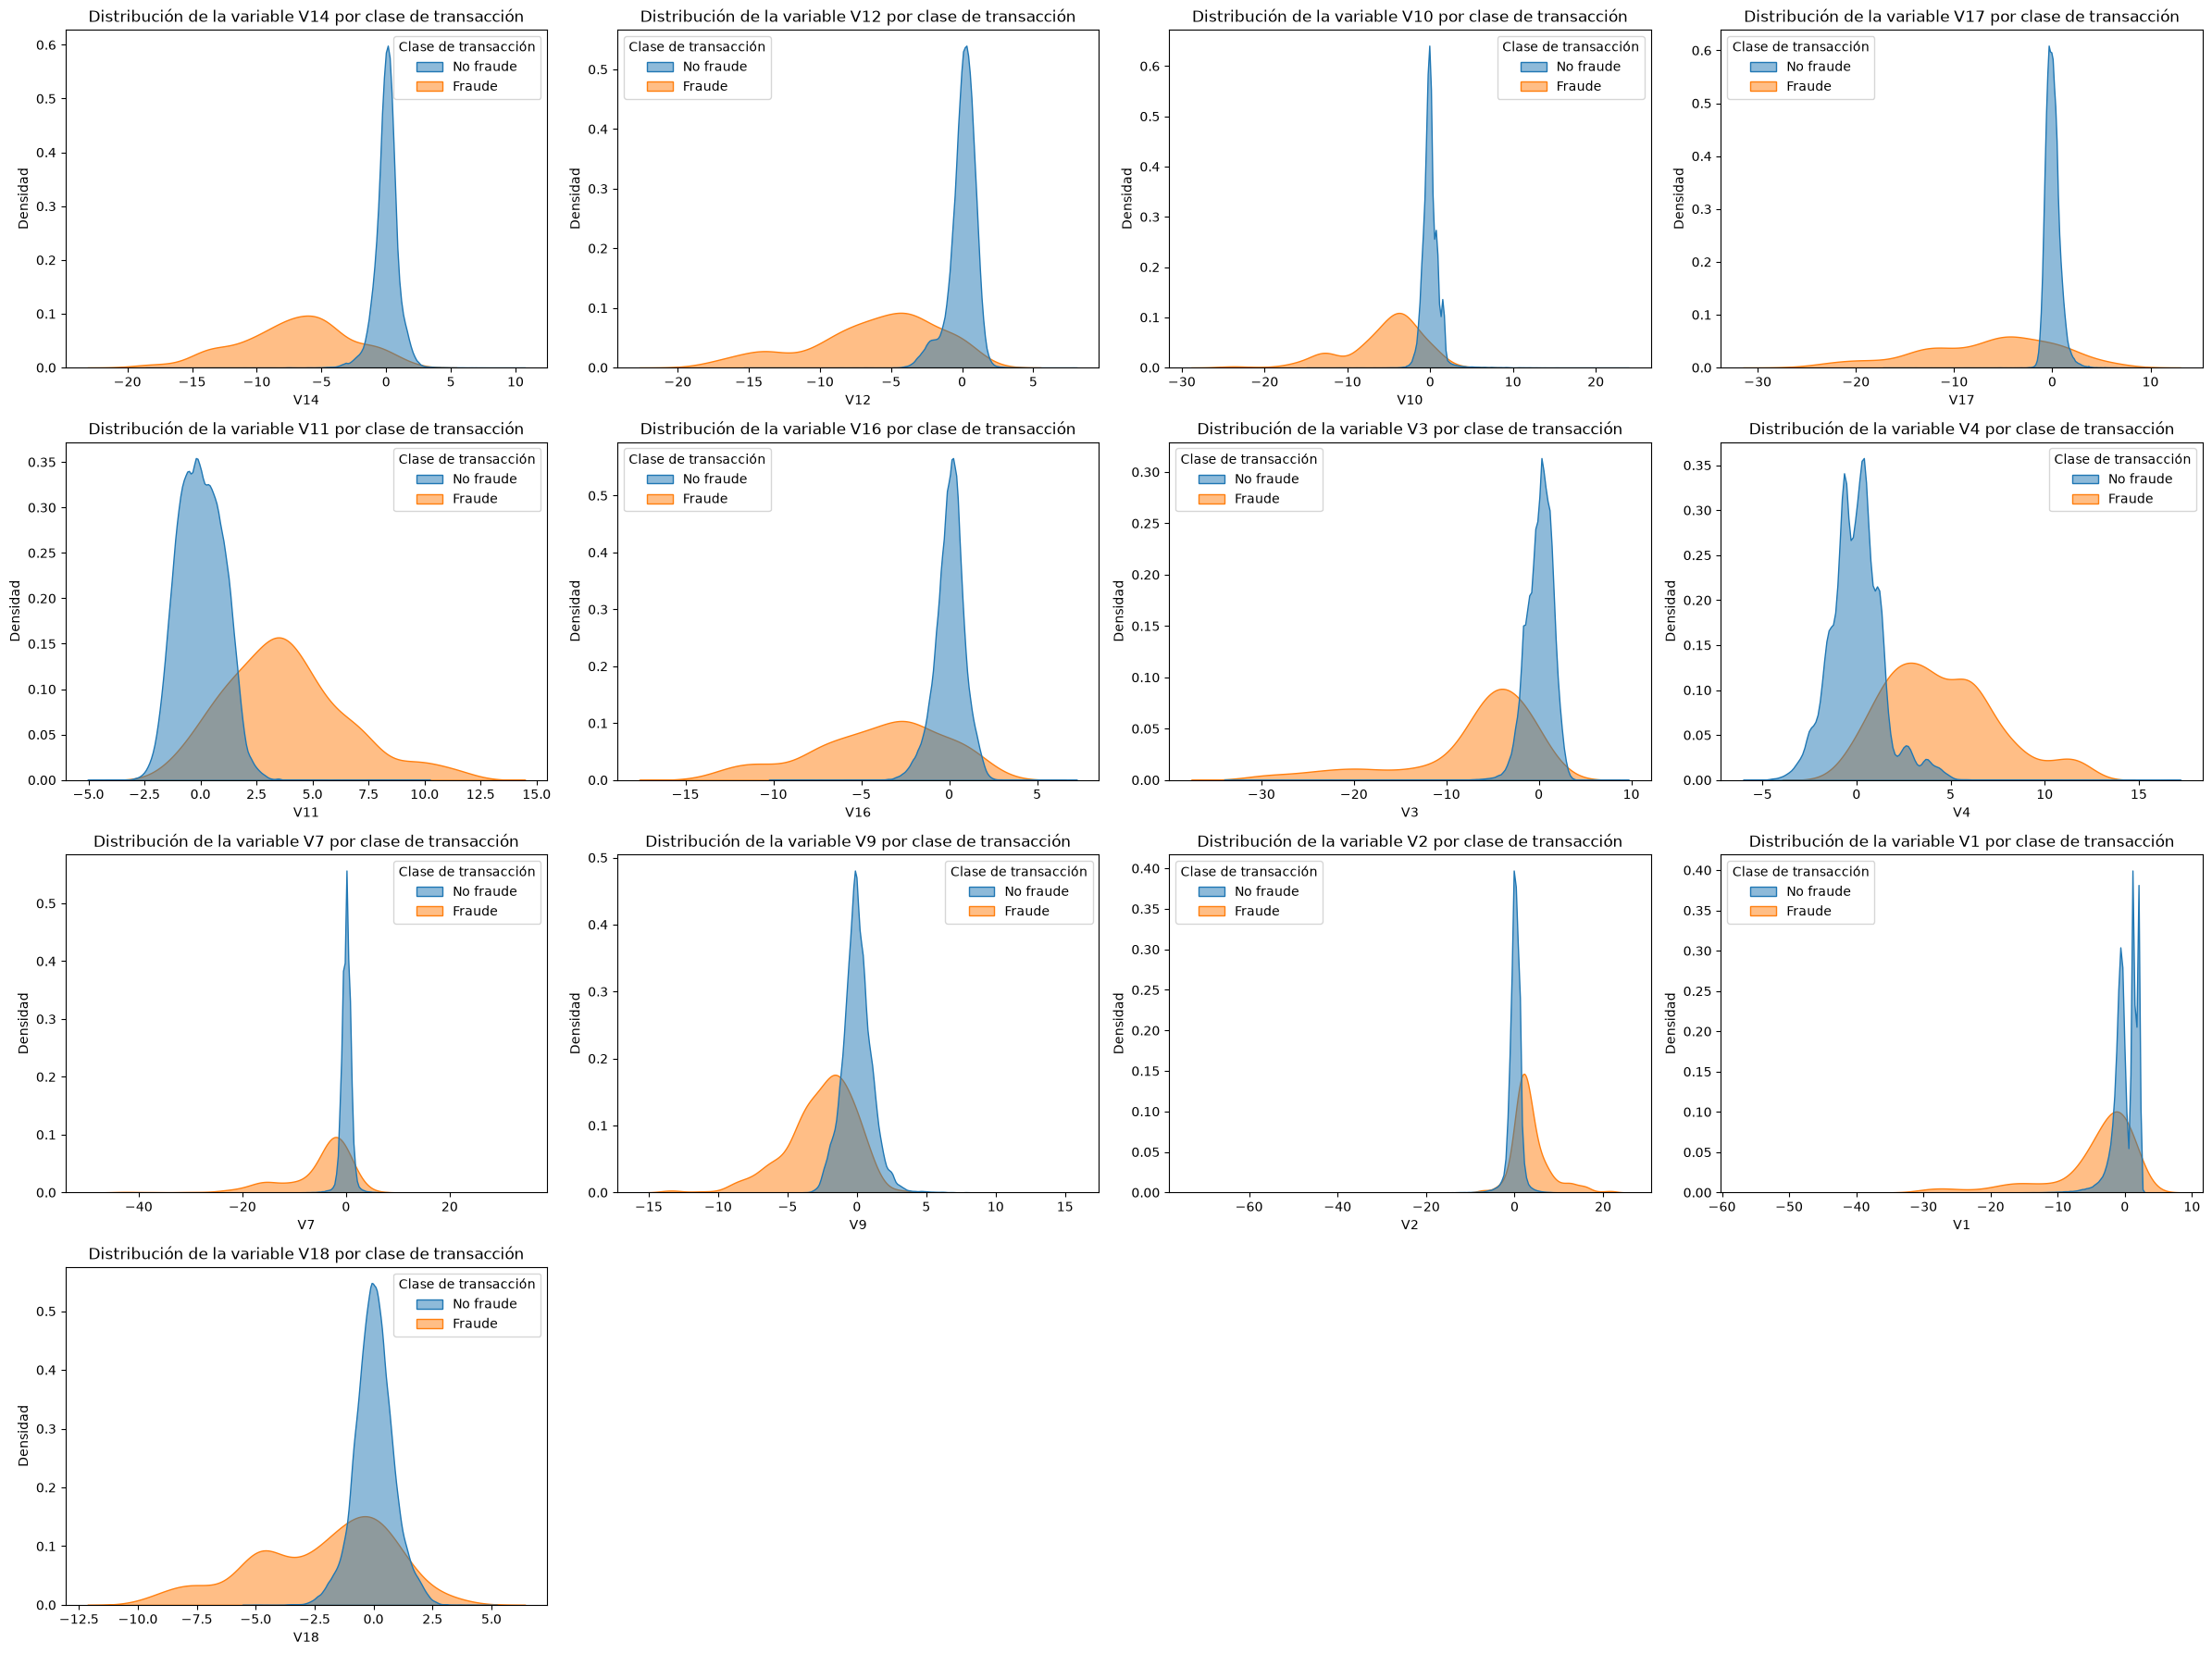

In [328]:
fig, axes = plt.subplots(5, 4, figsize=(24, 22))

for ax, col in zip(axes.flatten(), top_lista):
    sns.kdeplot(data=df_plot, x=col, hue='Tipo', fill=True, common_norm=False, alpha=0.5, ax=ax)
    ax.set_title(f'Distribución de la variable {col} por clase de transacción')
    ax.set_xlabel(col)
    ax.set_ylabel('Densidad')
    ax.get_legend().set_title('Clase de transacción')

for ax in axes.flat[len(top_lista):]:
    ax.set_visible(False)
    
fig.tight_layout()
plt.show()

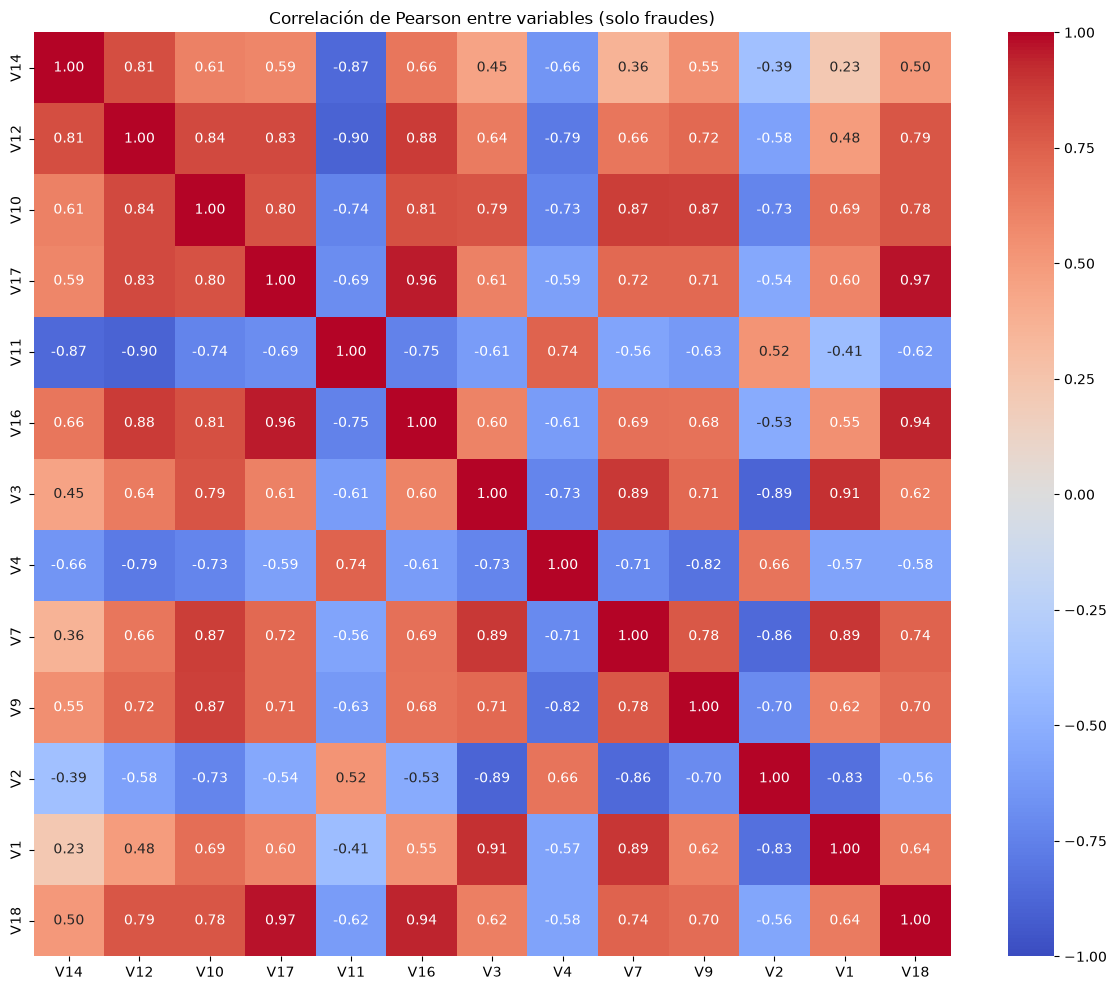

In [329]:
corr_pr_lista_fraude = df_train.loc[df_train['Class'] == 1, top_lista].corr()

plt.figure(figsize=(12, 10))
sns.heatmap(
    corr_pr_lista_fraude, cmap='coolwarm',
    annot=True, fmt='.2f',
    center=0, vmin=-1, vmax=1
)
plt.title('Correlación de Pearson entre variables (solo fraudes)')
plt.tight_layout()
plt.show()

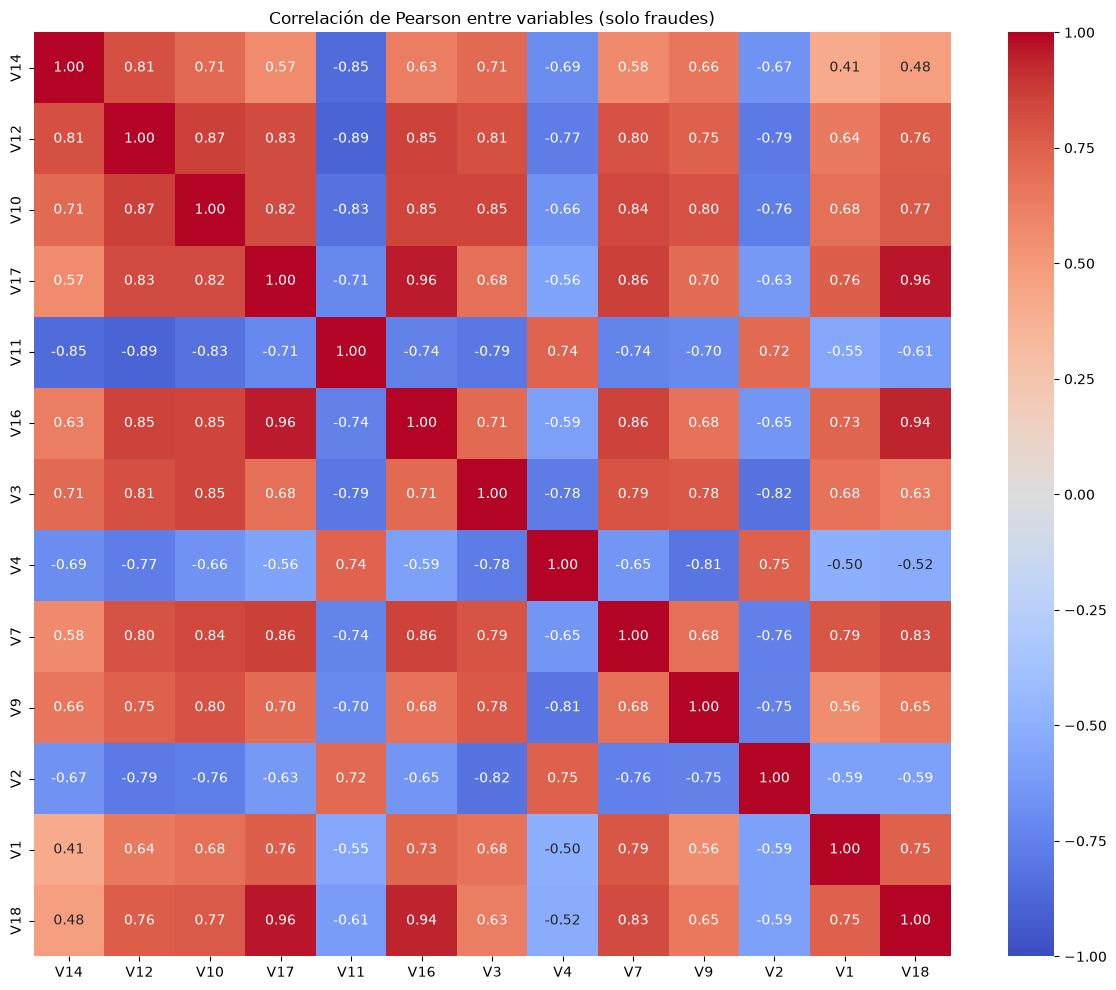

In [330]:
corr_sp_lista_fraude = df_train.loc[df_train['Class'] == 1, top_lista].corr(method = 'spearman')

plt.figure(figsize=(12, 10))
sns.heatmap(
    corr_sp_lista_fraude, cmap='coolwarm',
    annot=True, fmt='.2f',
    center=0, vmin=-1, vmax=1
)
plt.title('Correlación de Pearson entre variables (solo fraudes)')
plt.tight_layout()
plt.show()

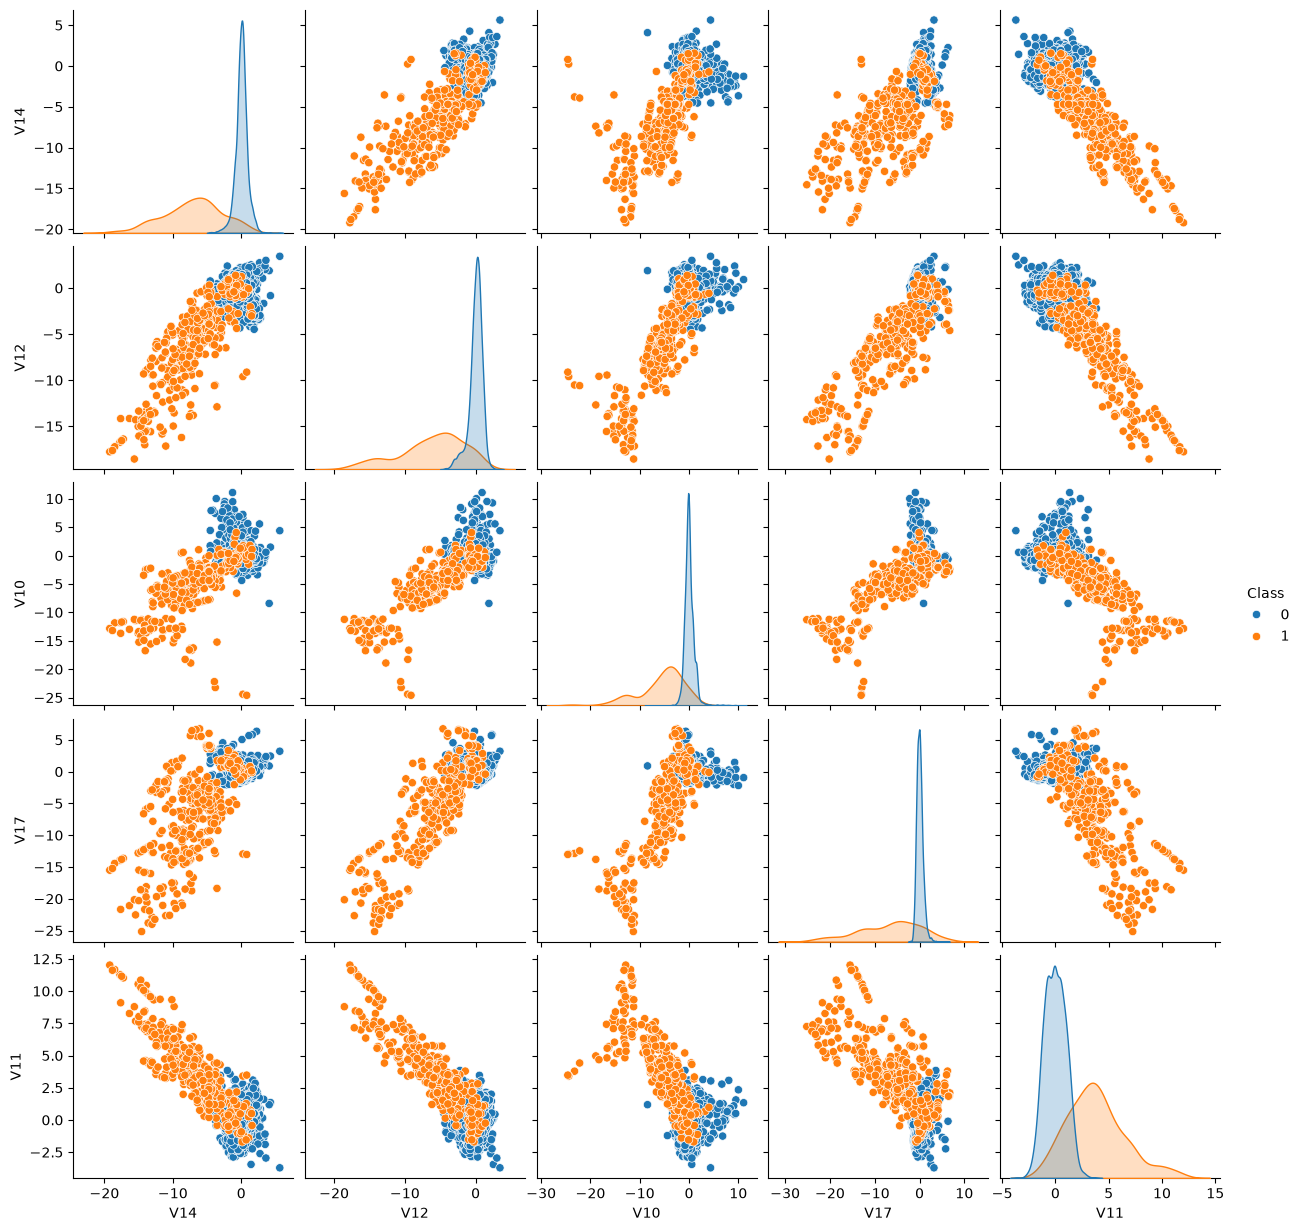

In [331]:
sns.pairplot(muestra, vars=top_5, hue='Class', diag_kws={'common_norm': False})
plt.show()